# Searching for the model's algorithm switch: DAS in Qwen3-8B (demo)

**Artifact `art_veI9l_Rb9wDY` (iteration 7, experiment 33).** bf16 **Qwen3-8B** (revision `b968826d`, thinking off)
almost always writes one *default* algorithm per coding task: **Dijkstra** for the weighted-shortest-path task T2. A
prompt that bans the default (*"Write a correct solution that does not use Dijkstra's algorithm."*) or forces an
alternative (*"Implement Floyd-Warshall for this task."*) makes it write another one. The artifact asks whether that
choice is carried by a **low-rank linear subspace** of the task-specification hidden states.

**Method: distributed alignment search (DAS).** One orthonormal map $R$ (4096 × 16, nested ranks $k$ = 1, 2, 4,
8, 16) is fitted on teacher-forced pairs. At decoder blocks 12-23 and the task-spec positions, it swaps only the
rank-$k$ part of a *source* prompt's states (a ban or a forced prompt) into a *base* prompt's states (a neutral twin):

$$h_{base} \leftarrow h_{base} + (h_{source} - h_{base})\,R_k^\top R_k$$

It is then tested in **held-out generation**: N = 30 common-random-number (CRN) slots, with programs scored by
hidden tests and frozen labellers. The edit is compared with the **full-state exchange** at the same site (the
ceiling) and with controls: random rank-$k$ subspaces, permuted-label DAS, read-position DAS, DIM-1, PCA-16, a null
source and a random-init network.

**Headline results (full run: 4,500 programs, about 1.6 GPU-hours on one RTX 4090).**
- **Steering works.** A rank-2 DAS edit moves the T2 ban to Bellman-Ford/SPFA on 12/30 slots. The full-state
  exchange gets 11/30, the unedited base 1/30, and random subspaces at most 1/30.
- **But it is not a clean variable.** The committed controls fail: permuted-label DAS also transfers (0.47), and a
  random-init network admits an equally good teacher-forced fit. So **P1 = FAIL (NOT SUPPORTED)**. What was found
  is a strong low-rank *steering handle*, not a clean causal variable.
- **Geometry.** In $R_{16}$ coordinates, bans leave the paraphrase cloud along the Dijkstra → Bellman-Ford
  (runner-up) axis. Random **seeds** (`seed=d32qxk4nt43`, `seed=(horse chair roof love)`) and *"Make a new
  algorithm."* stay inside it, and behaviour agrees: Dijkstra on 30/30.

**What this notebook runs (CPU only, under a minute after installs).** `method.py` drives GPU stages that need a
24 GB GPU and the 16 GB model, so they cannot run in Colab. The notebook keeps `method.py` intact but switched off.
It then re-runs the artifact's own **`report` stage** (`src/analysis7.py`, `src/m7.py`, `src/figures7.py`, copied
with minimal changes) on a 100-row T2 subset of the labelled generations in `mini_demo_data.json`. That includes
the manifold analysis, run on the real 151 × 16 $R_{16}$ activation coordinates.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Every package this demo imports is pre-installed on Colab: it re-runs the CPU analyses only
# (the GPU stages' torch / transformers / accelerate stack is not needed).

# numpy, scipy, scikit-learn, matplotlib, pandas: pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# method.py
import subprocess
import sys
from pathlib import Path

# src/analysis7.py, src/m7.py, src/figures7.py, src/stats6.py, src/cfg.py
import json
import math
from collections import Counter, defaultdict
from typing import Any

import matplotlib.pyplot as plt   # figures7.py also called matplotlib.use("Agg"); dropped so figures show inline
import numpy as np
from scipy import stats

# notebook additions: tables and timing
import time

import pandas as pd
from IPython.display import display

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 80)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-7/experiment-33/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["method_name"])
print("model:", data["metadata"]["model"], "| programs in the full run:", data["metadata"]["n_rows"])
print({d["dataset"]: len(d["examples"]) for d in data["datasets"]})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Finding the model's hidden algorithm switch (iteration 7, bf16 Qwen3-8B)
model: Qwen/Qwen3-8B@b968826d (bf16, thinking off) | programs in the full run: 4500
{'T2_weighted_shortest_path': 100}


## Configuration

Every tunable parameter is set here. The GPU switches stay off in Colab. The analysis parameters control how much
resampling the CPU analyses do. Their original values are in the comments, and the run below uses them, because
the whole report stage takes seconds.

In [5]:
# ---- pipeline switches (method.py) ----
RUN_FULL_PIPELINE = False   # True only inside the full artifact folder (src/, .venv, Qwen3-8B weights, a 24 GB GPU)
PIPELINE_STAGES = []        # method.py stages to run when RUN_FULL_PIPELINE (empty = every stage, in order)
TASKS = ["T2"]              # original: T2, T10, T03 (the demo data holds the T2 dataset)

# ---- analysis parameters (original values in comments) ----
# (scaled 20 -> 200 -> 2000, 1 -> 2 -> 4, (10,) -> (5, 10, 15), 50 -> 200 -> 1000; whole notebook ~20 s)
BOOT = 2000                 # slot-cluster bootstrap reps for recovery CIs (< 100 -> no CI)   original: 2000
MDS_N_INIT = 4              # metric-MDS restarts on the R16 points                           original: 4
ISOMAP_NEIGHBORS = 10       # Isomap kNN                                                      original: 10
GEODESIC_KS = (5, 10, 15)   # kNN graphs for geodesic distances (keep 10: F5 reads it)        original: (5, 10, 15)
LOS_NULL_DRAWS = 1000       # random-relabel draws, leave-one-survivor placement test         original: 1000

## 1. The entry point: `method.py`

`method.py` (the artifact's demo file) runs every stage in the order it was run. Each stage is a script under
`src/`, and the GPU stages resume where they stopped.

| stage | script | what it does |
|---|---|---|
| `prompts` | `src/prompts7.py` | every prompt record: bans W1-W5, 12-noun neutral twins, forced *Implement Y* × 5 template families, padding twins, M prompts |
| `commit0` | `src/prereg7.py` | pre-registration (design, thresholds, predictions) in a sha256 hash chain |
| `utest`, `s0` | `src/run_gpu7.py` | GPU unit tests; Stage 0, which records the algorithm each prompt makes the model write |
| `targets` | `stages_b7.stage_targets` | kept algorithms Y, the ban's landing set, target programs for teacher forcing |
| `profile` | `src/run_gpu7.py profile` | teacher-forced layer profile + generation confirmation, which sets the site |
| `fit`, `fitly` | `src/run_gpu7.py` | DAS fits: the committed contrastive objective (it diverged) and the amended LME_Y objective (used), with controls |
| `gen` | `src/run_gpu7.py gen` | held-out generation of every arm on N = 30 CRN slots |
| `after` | `scripts/run_gpu_after.sh` | λ sweep (R), M states, the third task T03, a random-init network |
| **`report`** | **`src/report7.py`** | **every analysis + figures (re-run in this notebook)** |
| `novelty`, `outputs`, `audit` | `src/novelty6.py`, `src/outputs7.py`, `audit/rederive.py` | novelty audit; `method_out.json`; independent re-derivation |

The code below is `method.py`, changed only where marked `# notebook:`. `ROOT` comes from the working directory,
because a notebook has no `__file__`. The stage list comes from the config cell, not `sys.argv`. And `main()` runs
only when `RUN_FULL_PIPELINE = True`, which needs the full artifact folder with its `.venv`, the Qwen3-8B weights
and a 24 GB CUDA GPU. Here it only prints the stage order.

In [6]:
#!/usr/bin/env python3
"""Iteration 7 entry point: DAS localisation of the planned algorithm in bf16 Qwen3-8B, validated by generation.

Runs every stage in the order it was run (each stage is resumable; GPU stages skip finished sample ids / files):
  prompts   src/prompts7.py                 all prompt records + CPU tests (prompts/prompts7.jsonl)
  commit0   src/prereg7.py                  commit #0 (design, thresholds, predictions; hash chain)
  label     src/label7.py (background)      frozen labellers follow data/samples_raw.jsonl -> data/labels.jsonl
  utest     src/run_gpu7.py utest           U1-U8 (results/unit_tests_gpu.json)
  s0        src/run_gpu7.py s0              Stage 0 sampling T2, T10, T03
  targets   stages_b7.stage_targets         kept Y, ban landing set, target programs (commit1_<task>_v2)
  profile   src/run_gpu7.py profile         layer profile + generation confirmation -> site (commit1b_<task>)
  fit       src/run_gpu7.py fit/fitlight    committed contrastive DAS fits + controls (commit2_<task>)
  fitly     src/run_gpu7.py fitly           amendment 1: bounded LME_Y maps (MAIN_LY, PERM_LY, RPOS_LY)
  tfeval    src/run_gpu7.py tfeval          held-out teacher-forced evaluation
  gen       src/run_gpu7.py gen,genpilot    held-out generation (MAIN_LY full cell set; MAIN 10-slot pilot)
  after     scripts/run_gpu_after.sh        R sweep + M states (T2), third task T03, random-init network (T2)
  report    src/report7.py                  every analysis + figures (results/*.json, figures/)
  novelty   src/novelty6.py                 two-family novelty audit of correct 'other' programs
  outputs   src/outputs7.py                 method_out.json (+ full_/mini_/preview_), schema-validated
  audit     audit/rederive.py               independent stdlib re-derivation + placebo tests

usage: .venv/bin/python method.py [stage ...]   (no argument = the whole pipeline)
"""

ROOT = Path.cwd()  # notebook: no __file__ (original: Path(__file__).resolve().parent)
PY = str(ROOT / ".venv" / "bin" / "python")


def run(*args: str) -> None:
    print("+", " ".join(args), flush=True)
    subprocess.run(list(args), cwd=ROOT, check=True)


STAGES = {
    "prompts": lambda: run(PY, "src/prompts7.py"),
    "commit0": lambda: run(PY, "src/prereg7.py"),
    "utest": lambda: run(PY, "src/run_gpu7.py", "utest", "--tasks", "T2"),
    "s0": lambda: run(PY, "src/run_gpu7.py", "s0", "--tasks", "T2,T10,T03"),
    "targets": lambda: run(PY, "-c", "import sys; sys.path.insert(0,'src'); from cfg import setup_logging; "
                                     "setup_logging('targets7'); from prompts7 import load_tokenizer; import stages_b7 "
                                     "as B; tok=load_tokenizer(); [B.stage_targets(t, tok) for t in "
                                     "('T2','T10','T03')]"),
    "profile": lambda: run(PY, "src/run_gpu7.py", "profile", "--tasks", "T2,T10"),
    "fit": lambda: (run(PY, "src/run_gpu7.py", "fit", "--tasks", "T2"),
                    run(PY, "src/run_gpu7.py", "fitlight", "--tasks", "T10")),
    "fitly": lambda: run(PY, "src/run_gpu7.py", "fitly,tfeval", "--tasks", "T2,T10"),
    "gen": lambda: run(PY, "src/run_gpu7.py", "gen,genpilot", "--tasks", "T2,T10"),
    "after": lambda: run("bash", "scripts/run_gpu_after.sh"),
    "report": lambda: run(PY, "src/report7.py"),
    "novelty": lambda: run(PY, "src/novelty6.py"),
    "outputs": lambda: run(PY, "src/outputs7.py"),
    "audit": lambda: run("python3", "audit/rederive.py"),
}


def main() -> None:
    want = PIPELINE_STAGES or list(STAGES)  # notebook: config cell (original: sys.argv[1:])
    label = None
    if any(s in want for s in ("utest", "s0", "profile", "fit", "fitly", "gen", "after")):
        label = subprocess.Popen([PY, "src/label7.py"], cwd=ROOT)
    try:
        for s in want:
            STAGES[s]()
    finally:
        if label is not None:
            (ROOT / "results" / "gpu_all_done.flag").touch()
            label.wait()


if RUN_FULL_PIPELINE:  # notebook: original `if __name__ == "__main__": main()`
    main()
else:
    print("RUN_FULL_PIPELINE = False: GPU pipeline not run. Stages, in the order they ran:")
    print("  " + " -> ".join(STAGES))

RUN_FULL_PIPELINE = False: GPU pipeline not run. Stages, in the order they ran:
  prompts -> commit0 -> utest -> s0 -> targets -> profile -> fit -> fitly -> gen -> after -> report -> novelty -> outputs -> audit


## 2. The demo data

`mini_demo_data.json` holds one dataset, `T2_weighted_shortest_path`, with 100 examples in the artifact's
`exp_gen_sol_out` format. Each example is one **(source group, CRN slot)** pair:
- `input`: the base prompt.
- `output`: the algorithm the source carries.
- `predict_<arm>`: `'<label>|<pass|fail>'` for every arm run on that slot. The label is the mechanism of the
  generated program; pass/fail says whether it passed the hidden tests.
- `metadata_code_<arm>`: the program itself.
- `metadata_edit_<arm>`: the edit that was applied.

| group | slots | arms |
|---|---|---|
| `ban_W5` | 30 | `BASE_W5` (unedited twin); `DASLY_ban_k{1,2,4,8,16}` (the DAS edit); controls `RAND_*`, `PERMLY_*`, `RPOSLY_*`, `RPOSFULL_ban`, `DIM1_ban`, `PCA16_ban`; `DAS_ban_k*` (committed-map pilot); `DASLY2_*` (second init seed); `MGEN_*` (seeds and instructions); `BASE_PAD` |
| `confirm_ban` | 30 | `FULL_ban_L18`, `FULL_ban_band`: the full-state exchange (the ceiling) |
| `forced_floyd` | 30 | `FULL_F_floyd`, `DASLY_F_floyd_k{1,4,16}`, random / permuted controls, pilot and seed-2 arms |
| `heldout_W4` | 10 | `BASE_W4`, `FULL_W4`, `DASLY_W4_k2` |

Every arm of a slot shares the slot's uniform random stream (common random numbers). Two arms therefore differ on
a slot only because of the edit, which is what makes the paired (McNemar) comparisons exact. The cell below shows
one slot where the unedited model writes Dijkstra and the rank-2 DAS edit makes it write Bellman-Ford.

In [7]:
ds = data["datasets"][0]
examples = ds["examples"]
print(ds["dataset"], "|", len(examples), "examples |", dict(Counter(e["metadata_group"] for e in examples)))
ex = next(e for e in examples if e["metadata_group"] == "ban_W5" and e["predict_BASE_W5"] == "dijkstra|pass"
          and e["predict_DASLY_ban_k2"] == "bf_spfa|pass")
print(f"\nslot {ex['metadata_slot']}, base prompt (input):\n{ex['input'][:900]} ...")
print("\nalgorithm the source carries (output):", ex["output"])
arms = sorted(k[len("predict_"):] for k in ex if k.startswith("predict_"))
print(f"\n{len(arms)} arms on this slot:", ", ".join(arms))
for arm in ("BASE_W5", "DASLY_ban_k2"):
    print(f"\n----- {arm}: {ex['predict_' + arm]}   edit = {ex['metadata_edit_' + arm]}")
    print("\n".join(ex["metadata_code_" + arm].splitlines()[:16]))

T2_weighted_shortest_path | 100 examples | {'ban_W5': 30, 'confirm_ban': 30, 'forced_floyd': 30, 'heldout_W4': 10}

slot 5, base prompt (input):
Write a correct solution that does not use mother. . . .

Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most 600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum total weight of a path from s to t as an int, 0 if s equals t, and -1 if t cannot be reached from s.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation. ...

algorithm the source carries (output): bf_spfa

31 arms on this slot: BASE_PAD, BASE_W5, DASLY2_ban_k1, DASLY2_b

## 3. Unpack the data into the artifact's folder layout

The original analysis code reads files under the artifact folder (`cfg.ROOT`):
- `data/labels.jsonl`: one row per generated program;
- `results/*.json`: saved outputs of the GPU stages;
- `prompts/prompts7.jsonl`;
- `cache/m_states_T2.npz`;
- `inputs/`.

This cell rebuilds exactly those files from `data` under `./demo_artifact/`, so the analysis code keeps its
original file reads.

Two inputs need rows outside the 100-example subset, so both come from the saved full-run results:
- the implemented counts that size the manifold centroids, which need all 4,500 labels plus two earlier artifacts'
  samples;
- exp9's leave-one-survivor behaviour table.

In [8]:
ROOT = Path("demo_artifact").resolve()  # plays the role of the artifact folder (cfg.ROOT)
INPUTS = ROOT / "inputs"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
for _d in (ROOT / "data", RESULTS_DIR, FIG_DIR, INPUTS, ROOT / "prompts", ROOT / "cache"):
    _d.mkdir(parents=True, exist_ok=True)
meta = data["metadata"]
extra = meta["demo_inputs"]

# 1) data/labels.jsonl: unpack predict_<arm> = '<label>|<pass|fail>' (+ program and edit metadata), one row per program
rows = []
for ex in examples:
    for key, val in ex.items():
        if not key.startswith("predict_"):
            continue
        arm = key[len("predict_"):]
        label, verdict = val.rsplit("|", 1)
        edit = json.loads(ex.get(f"metadata_edit_{arm}") or "{}")
        rows.append({"sample_id": f"{ex['metadata_task']}|{arm}|{ex['metadata_slot']}", "task": ex["metadata_task"],
                     "arm": arm, "slot_index": ex["metadata_slot"], "label": None if label == "None" else label,
                     "passed": verdict == "pass", "code": ex.get(f"metadata_code_{arm}", ""),
                     "finish_reason": edit.get("finish_reason"), "n_new_tokens": edit.get("n_new_tokens"),
                     "labeller_source": edit.get("labeller_source")})
with open(ROOT / "data" / "labels.jsonl", "w") as fh:
    fh.writelines(json.dumps(r) + "\n" for r in rows)

# 2) results/*.json that the analyses and figures read (saved outputs of the GPU stages)
for name in ("site_T2", "kstar_T2", "targets_T2", "tf_eval_T2", "tf_eval_T2_LY"):
    (RESULTS_DIR / f"{name}.json").write_text(json.dumps(meta[name]))
for name in ("randinit_ly_T2", "seed2_T2"):
    (RESULTS_DIR / f"{name}.json").write_text(json.dumps(extra[name]))

# 3) prompts/prompts7.jsonl (records of the 151 prompts M places) + cache/m_states_T2.npz (their R16 coordinates)
with open(ROOT / "prompts" / "prompts7.jsonl", "w") as fh:
    fh.writelines(json.dumps(r) + "\n" for r in extra["m_prompts_T2"])
ms = extra["m_states_T2"]
np.savez(ROOT / "cache" / "m_states_T2.npz", keys=np.array(ms["keys"]), z=np.array(ms["z"], dtype=np.float32),
         block=ms["block"])

# 4) inputs/: exp9's leave-one-survivor behaviour table and the saved implemented counts
(INPUTS / "exp9_los.json").write_text(json.dumps(meta["m_manifold"]["exp9_los_behaviour"]))
(INPUTS / "implemented_counts_T2.json").write_text(json.dumps(meta["m_manifold"]["implemented_counts"]))

print(f"{len(rows)} labelled programs in {len({r['arm'] for r in rows})} arms -> {ROOT.name}/data/labels.jsonl")
print(f"R16 coordinates: {len(ms['keys'])} prompts x {len(ms['z'][0])} dims (block {ms['block']}) -> {ROOT.name}/cache/")

1160 labelled programs in 46 arms -> demo_artifact/data/labels.jsonl
R16 coordinates: 151 prompts x 16 dims (block 18) -> demo_artifact/cache/


## 4. Constants and helpers

These definitions are copied as they are, from three files:
- `src/cfg7.py`: task defaults, the label catalogue, the ranks, the seed and instruction strings;
- `src/cfg.py`: the JSON helpers;
- `src/stats6.py`: the exact McNemar test, Clopper-Pearson intervals and the Holm correction.

Only the definitions the analyses use are copied, and `ROOT` points at the unpacked demo folder.

In [9]:
# ---- src/cfg7.py ----
TASKS7 = ("T2", "T10", "T03")
CORE7 = ("T2", "T10")
DEFAULT7 = {"T2": "dijkstra", "T10": "union_find", "T03": "full_sort"}
# label vocabulary of the frozen labellers (exp8 suite for T2, exp11 bench for T10/T03)
CATALOGUE7 = {
    "T2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"],
    "T10": ["bfs", "dfs", "union_find", "label_propagation"],
    "T03": ["full_sort", "size_k_heap", "heapify_pop", "quickselect", "median_of_medians", "counting_sort"],
}
RANKS = (1, 2, 4, 8, 16)
K_MAX = 16
PROFILE_LAYERS = tuple(range(10, 27, 2))           # 10, 12, ..., 26
BAND = tuple(range(12, 24))                          # declared fallback band 12-23
SEED_STRINGS = {"seed_rand1": "seed=d32qxk4nt43", "seed_rand2": "seed=(horse chair roof love)"}
INSTR = {"instr_new": "Make a new algorithm.",
         # exp18 src/config.py LONGFORM['LF2'] verbatim (ITER3/gen_art_experiment_18)
         "instr_novel": ("Make a fully novel algorithm never seen before for this task. Before writing any code, write "
                         "a design rationale of about 2,000 words that explains the idea, why no one has used it "
                         "before, and why it is correct.")}
PROMPTS7 = ROOT / "prompts" / "prompts7.jsonl"
LABELS7 = ROOT / "data" / "labels.jsonl"
CACHE7 = ROOT / "cache"
MAPS7 = ROOT / "das_maps"


def results7(name: str) -> Path:
    return RESULTS_DIR / name


# ---- src/cfg.py ----
def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    print(f"skipping malformed line in {p.name}")  # notebook: print (original: logger.warning)
    return out


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


# ---- src/stats6.py ----
def mcnemar_exact(b: int, c: int) -> float:
    """Two-sided exact McNemar p-value on b and c discordant pairs."""
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, stats.binomtest(min(b, c), n, 0.5, alternative="two-sided").pvalue))


def clopper_pearson(k: int, n: int, level: float = 0.95) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    a = 1 - level
    lo = stats.beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return float(lo), float(hi)


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted([(k, v) for k, v in pvals.items() if v is not None and not math.isnan(v)], key=lambda x: x[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


# ---- src/report7.py ----
def fmt(x: Any, nd: int = 2) -> str:
    if x is None:
        return "-"
    if isinstance(x, float):
        return f"{x:.{nd}f}"
    return str(x)

### Figure code (`src/figures7.py`)

The artifact's figure functions F1-F6 are copied as they are. `save()` still writes PDF + PNG into
`demo_artifact/figures/`, and now also shows each figure inline: the original closed it. F7 (dormant checks) and F8
(fit curves) are not drawn, because their inputs (the 4096-d natural-state caches and the per-step fit curves) are not
shipped.

In [10]:
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 7.5,
                     "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False})
COL = {"dijkstra": "#4c72b0", "bf_spfa": "#dd8452", "bidijkstra": "#55a868", "floyd": "#c44e52", "dial": "#8172b3",
       "bfs": "#dd8452", "dfs": "#c44e52", "union_find": "#4c72b0", "label_propagation": "#8172b3",
       "full_sort": "#4c72b0", "quickselect": "#dd8452", "size_k_heap": "#55a868", "heapify_pop": "#c44e52",
       "median_of_medians": "#8172b3", "counting_sort": "#937860", "other": "#999999", "invalid": "#dddddd"}


def save(fig: Any, name: str) -> None:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()  # notebook: show inline (original: plt.close(fig))


def f1(tasks: list[str]) -> None:
    fig, axes = plt.subplots(2, len(tasks), figsize=(4.2 * len(tasks), 6.2), squeeze=False)
    for j, t in enumerate(tasks):
        p = results7(f"site_{t}.json")
        if not p.exists():
            continue
        s = read_json(p)
        ax = axes[0, j]
        for kind, c in (("ban", "#c44e52"), ("forced", "#4c72b0")):
            d = s["profile"]["by_kind"].get(kind)
            if not d:
                continue
            ax.plot(PROFILE_LAYERS, [d[f"full@{l}"] for l in PROFILE_LAYERS], "-o", color=c, ms=3,
                    label=f"{kind} source, single block")
            ax.axhline(d["band12-23"], color=c, ls="--", lw=1, label=f"{kind}, band 12-23")
            ax.axhline(d["rpos_all"], color=c, ls=":", lw=1, label=f"{kind}, read position (all blocks)")
        ax.set_title(f"{t}: teacher-forced full-state exchange")
        ax.set_xlabel("decoder block (output) exchanged at spec positions")
        ax.set_ylabel("contrast gain C - C_none (nats)")
        ax.legend(frameon=False)
        ax = axes[1, j]
        cf = s["confirmation"]
        L = s["L_star"]
        bars = [("ban: base", cf["BASE_W5"]["correct_Y"]), (f"ban: full L{L}", cf[f"FULL_ban_L{L}"]["correct_Y"]),
                ("ban: full band", cf["FULL_ban_band"]["correct_Y"])]
        Yc = cf.get("forced_Y")
        if Yc:
            bars += [(f"F3 {Yc}: base", cf[f"PADBASE_F3_{Yc}"]["correct_Y"]),
                     (f"F3 {Yc}: full L{L}", cf[f"FULLF3_{Yc}_L{L}"]["correct_Y"]),
                     (f"F3 {Yc}: full band", cf[f"FULLF3_{Yc}_band"]["correct_Y"])]
        ax.bar(range(len(bars)), [b[1] / 30 for b in bars], color=["#bbbbbb", "#c44e52", "#c44e52", "#bbbbbb",
                                                                   "#4c72b0", "#4c72b0"][:len(bars)])
        for i, b in enumerate(bars):
            ax.text(i, b[1] / 30 + 0.02, f"{b[1]}/30", ha="center", fontsize=7)
        ax.set_xticks(range(len(bars)))
        ax.set_xticklabels([b[0] for b in bars], rotation=30, ha="right")
        ax.set_ylim(0, 1.1)
        ax.set_ylabel("correct source-Y share (N = 30)")
        ax.set_title(f"{t}: generation confirmation -> site = {s['site']}")
    fig.tight_layout()
    save(fig, "F1_layer_profile")


def f2(p1: dict[str, Any], tasks: list[str]) -> None:
    fig, axes = plt.subplots(2, len(tasks), figsize=(4.2 * len(tasks), 6.4), squeeze=False)
    for j, t in enumerate(tasks):
        r = p1["tasks"].get(t)
        ax = axes[0, j]
        if r:
            ks = [k for k in RANKS if r["per_k"].get(k, {}).get("recovery") is not None]
            ys = [r["per_k"][k]["recovery"] for k in ks]
            ci = [r["per_k"][k].get("recovery_ci") or [None, None] for k in ks]
            ax.plot(ks, ys, "-o", color="#4c72b0", label="DAS (LME_Y map), pooled sources")
            for k, (lo, hi) in zip(ks, ci):
                if lo is not None:
                    ax.plot([k, k], [lo, hi], color="#4c72b0", lw=1)
            for k in (16, r.get("k_star")):
                e = r["per_k"].get(k) or {}
                if e.get("random_recovery") is not None:
                    ax.plot(k, e["random_recovery"], "s", color="#999999", label="random rank-k" if k == 16 else None)
            ctrl = read_json(results7(f"p1_controls_{t}.json")) if results7(f"p1_controls_{t}.json").exists() else {}
            full = (r["per_source"].get("ban") or {}).get("full_transfer") or 0
            for arm, mk, lab in (("RPOSLY_ban_k16", "v", "read-position DAS k16"), ("DIM1_ban", "^", "DIM-1"),
                                 ("PCA16_ban", "D", "PCA-16")):
                e = ctrl.get(arm)
                if e and full > 0:
                    kk = 1 if arm == "DIM1_ban" else 16
                    ax.plot(kk, e["transfer"] / full, mk, color="#55a868" if "RPOS" in arm else "#8172b3", label=lab)
            pm = (r["per_source"].get("ban") or {}).get("perm") or {}
            for a, e in pm.items():
                if full > 0:
                    kk = int(a.rsplit("k", 1)[1])
                    ax.plot(kk, e["transfer"] / full, "x", color="#c44e52", label="permuted-label (ban)"
                            if kk == 16 else None)
        ax.axhline(0.8, color="k", ls=":", lw=0.8)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xscale("log", base=2)
        ax.set_xticks(RANKS)
        ax.set_xticklabels(RANKS)
        ax.set_xlabel("rank k")
        ax.set_ylabel("generation recovery (vs full-state, same site)")
        ax.set_title(f"{t}: held-out generation (N = 30 / source)")
        ax.legend(frameon=False, fontsize=6.5)
        ax = axes[1, j]
        p = results7(f"tf_eval_{t}_LY.json")
        q = results7(f"tf_eval_{t}.json")
        if p.exists():
            sm = read_json(p)["summary"]
            for kind, ls in (("ban", "-"), ("forced", "--")):
                d = sm.get(kind)
                if not d:
                    continue
                for nm, c in (("DASLY", "#4c72b0"), ("PERMLY", "#c44e52"), ("PROJLY", "#55a868")):
                    ys = [d.get(f"{nm}_k{k}", {}).get("tf_recovery") for k in RANKS]
                    ax.plot(RANKS, [np.nan if y is None else y for y in ys], ls, marker="o", ms=3, color=c,
                            label=f"{nm} ({kind})")
        if q.exists():
            sm = read_json(q)["summary"]
            for kind, ls in (("ban", "-"), ("forced", "--")):
                d = sm.get(kind)
                if not d:
                    continue
                ys = [np.mean([d.get(f"RAND{i}_k{k}", {}).get("tf_recovery") or 0 for i in (1, 2, 3)]) for k in RANKS]
                ax.plot(RANKS, ys, ls, marker="s", ms=3, color="#999999", label=f"random ({kind})")
        ax.axhline(1, color="k", ls=":", lw=0.8)
        ax.set_xscale("log", base=2)
        ax.set_xticks(RANKS)
        ax.set_xticklabels(RANKS)
        ax.set_xlabel("rank k")
        ax.set_ylabel("TF recovery of the contrast C")
        ax.set_title(f"{t}: teacher-forced (held-out pairs)")
        ax.legend(frameon=False, fontsize=6)
    fig.tight_layout()
    save(fig, "F2_recovery_vs_rank")


def f3(rt: dict[str, Any]) -> None:
    tasks = [t for t in rt if rt[t]["confusion"]]
    if not tasks:
        return
    cols = ["full", "k1", "k4", "k16"]
    fig, axes = plt.subplots(len(tasks), len(cols), figsize=(3.0 * len(cols), 2.3 * len(tasks)), squeeze=False)
    for i, t in enumerate(tasks):
        conf = rt[t]["confusion"]
        for j, c in enumerate(cols):
            ax = axes[i, j]
            if c not in conf:
                ax.axis("off")
                continue
            rows = list(conf[c])
            labs = CATALOGUE7[t] + ["other", "fail"]
            M = np.array([[conf[c][y].get(l, 0) for l in labs] for y in rows])
            ax.imshow(M, cmap="Blues", vmin=0, vmax=30)
            for a in range(M.shape[0]):
                for b in range(M.shape[1]):
                    if M[a, b]:
                        ax.text(b, a, int(M[a, b]), ha="center", va="center", fontsize=7)
            ax.set_xticks(range(len(labs)))
            ax.set_xticklabels(labs, rotation=45, ha="right", fontsize=6.5)
            ax.set_yticks(range(len(rows)))
            ax.set_yticklabels([f"forced {y}" for y in rows], fontsize=7)
            ax.set_title(f"{t}: {'full-state' if c == 'full' else 'DAS ' + c}", fontsize=8.5)
    fig.tight_layout()
    save(fig, "F3_routing_confusion")


def f4(m: dict[str, Any]) -> None:
    co = m["coords"]
    kinds = np.array(co["kind"])
    Ys = co["Y"]
    das = np.array(co["das12"])
    fig, axes = plt.subplots(2, 3, figsize=(13, 8.2))
    style = {"twin": ("o", "#bbbbbb", 12), "padtwin": ("o", "#dddddd", 10), "p0": ("*", "k", 80),
             "ban": ("X", "#c44e52", 45), "shamban": ("x", "#c44e52", 22), "multiban": ("P", "#8172b3", 40),
             "seed_rand1": ("^", "#55a868", 70), "seed_rand2": ("^", "#55a868", 70), "seed_sem": ("v", "#55a868", 70),
             "instr_new": ("s", "#937860", 60), "instr_novel": ("s", "#937860", 60)}
    for ax, XY, title in ((axes[0, 0], das, "(a) DAS-1 x DAS-2 (residual units)"),
                          (axes[0, 1], np.array(co["mds"]), f"(b) metric MDS of R16 coords (stress-1 "
                                                             f"{m['mds_stress1']:.3f})"),
                          (axes[0, 2], np.array(co["isomap"]), "(c) Isomap (kNN 10) of R16 coords")):
        for kd, (mk, c, sz) in style.items():
            sel = kinds == kd
            if sel.any():
                ax.scatter(XY[sel, 0], XY[sel, 1], marker=mk, c=c, s=sz, label=kd, lw=0.6)
        sel = kinds == "forced"
        for i in np.where(sel)[0]:
            ax.scatter(XY[i, 0], XY[i, 1], marker="D", s=26, c=COL.get(Ys[i], "#333"), edgecolor="k", lw=0.4)
        ax.set_title(title)
        if ax is axes[0, 0]:
            zb = np.array(co["zbar_das12"])
            for i, kd in enumerate(kinds):
                if kd in ("ban", "seed_rand1", "seed_rand2", "seed_sem", "instr_new", "instr_novel") and \
                        (kd != "ban" or True):
                    ax.annotate("", xy=XY[i], xytext=zb, arrowprops=dict(arrowstyle="->", lw=0.6, color="#555"))
            ax.set_xlabel("DAS-1 coordinate")
            ax.set_ylabel("DAS-2 coordinate")
    from matplotlib.lines import Line2D
    hs, ls_ = axes[0, 0].get_legend_handles_labels()
    for Y in sorted({y for y, kd in zip(Ys, kinds) if kd == "forced" and y}):
        hs.append(Line2D([], [], marker="D", ls="", color=COL.get(Y, "#333"), markeredgecolor="k", ms=5))
        ls_.append(f"forced {Y}")
    axes[0, 0].legend(hs, ls_, frameon=False, fontsize=5.5, ncol=2, loc="best")
    cent = co["centroids_das12"]
    for ax, (name, cnt) in zip(axes[1], [("twin (Stage 0)", m["implemented_counts"]["twin"]),
                                          ("Qwen3-8B-Base (exp24)", m["implemented_counts"]["base_model"]),
                                          ("knobs (edits + exp29 dirs)", m["implemented_counts"]["knobs"])]):
        ax.scatter(das[:, 0], das[:, 1], s=6, c="#dddddd")
        tot = max(1, sum(cnt.values()))
        for Y, xy in cent.items():
            n = cnt.get(Y, 0)
            ax.scatter([xy[0]], [xy[1]], s=40 + 900 * n / tot, c=COL.get(Y, "#333"), alpha=0.75, edgecolor="k")
            ax.annotate(f"{Y} ({n})", xy, fontsize=7, xytext=(4, 4), textcoords="offset points")
        ax.set_title(f"centroids sized by implemented count\nunder {name}", fontsize=8.5)
        ax.set_xlabel("DAS-1 coordinate")
        ax.set_ylabel("DAS-2 coordinate")
    fig.tight_layout()
    save(fig, "F4_causal_manifold")


def f5(m: dict[str, Any]) -> None:
    g = m["geodesic"].get("10") or m["geodesic"].get(10)
    if not g or not g["los_placement"]:
        return
    pl = g["los_placement"]
    cat = list(pl[0]["dist"])
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    w = 0.8 / len(cat)
    for i, a in enumerate(cat):
        ax.bar(np.arange(len(pl)) + i * w, [p["dist"][a] if np.isfinite(p["dist"][a]) else 0 for p in pl], w,
               color=COL.get(a, "#333"), label=a)
    ax.set_xticks(np.arange(len(pl)) + 0.4)
    ax.set_xticklabels([f"{p['w']}: keep {p['survivor']}" for p in pl], rotation=30, ha="right", fontsize=7)
    ax.set_ylabel("mean geodesic distance (kNN 10)")
    ax.set_title(f"T2 leave-one-survivor bans: survivor rank mean {g['mean_survivor_rank']:.2f} of 5 "
                 f"(random-relabel p {g['p_rank_le_observed']:.2f})")
    ax.legend(frameon=False, fontsize=7, ncol=5)
    fig.tight_layout()
    save(fig, "F5_topk_prohibition_placement")


def f6(r: dict[str, Any] | None) -> None:
    if not r:
        return
    lam = sorted(float(x) for x in r["curve"])
    cur = {float(k): v for k, v in r["curve"].items()}
    fig, ax = plt.subplots(figsize=(5, 3.4))
    ax.plot(lam, [cur[x]["correct_Y"] / cur[x]["n"] for x in lam], "o", color="#dd8452", label="correct Y share")
    ax.plot(lam, [cur[x]["correct_default"] / cur[x]["n"] for x in lam], "s", color="#4c72b0",
            label="correct default share")
    ax.plot(lam, [cur[x]["pass"] for x in lam], ":", color="#999", label="pass rate")
    xs = np.linspace(0, 1.5, 200)
    f = r["fit"]
    ax.plot(xs, 1 / (1 + np.exp(-(xs - f["lam0"]) / f["s"])), "-", color="#dd8452", lw=1,
            label=f"logistic: lam0 {f['lam0']:.2f}, width {f['width_10_90']:.2f}")
    ax.set_xlabel("lambda (interpolated DAS edit)")
    ax.set_ylabel("share of N = 20")
    ax.set_title("T2 discreteness of the plan coordinate")
    ax.legend(frameon=False)
    fig.tight_layout()
    save(fig, "F6_discreteness")

## 5. What the GPU stages found (saved results)

The stages `s0 → targets → profile → fit/fitly` need the model. Their saved outputs ship in the data file and set
up every analysis below:
- **Stage 0 / targets.** Forced *Implement Y* prompts make the model write Bellman-Ford/SPFA (17/20) and
  Floyd-Warshall (19/20), but not bidirectional Dijkstra or Dial. The W5 ban lands on **Bellman-Ford/SPFA**, the
  runner-up.
- **Site (plotted below with the original `f1`).** The teacher-forced full-state exchange peaks at block 18. In
  generation, though, exchanging the ban's states at block 18 alone moves 0/30 slots, while the band 12-23 moves
  11/30. So the committed band fallback fired.
- **Fits.** The committed contrastive objective diverged, to a validation gain of 1,873 nats against a full-state
  ceiling of about 14. The amended, bounded LME_Y map (`MAIN_LY`, the `DASLY_*` arms) carries every decisive cell.

Stage 0, forced 'Implement Y' (correct Y of 20): {'dijkstra': 20, 'bf_spfa': 17, 'bidijkstra': 0, 'floyd': 19, 'dial': 2}
kept Y: ['bf_spfa', 'floyd'] | ban landing set: ['bf_spfa'] | default: dijkstra
L* = 18 | site = band | k* = 2 | forced cells: ['bf_spfa', 'floyd']
committed contrastive map (MAIN): best validation gain 1873.4 nats -> diverged
amended LME_Y map (MAIN_LY):       best validation gain 14.86 nats


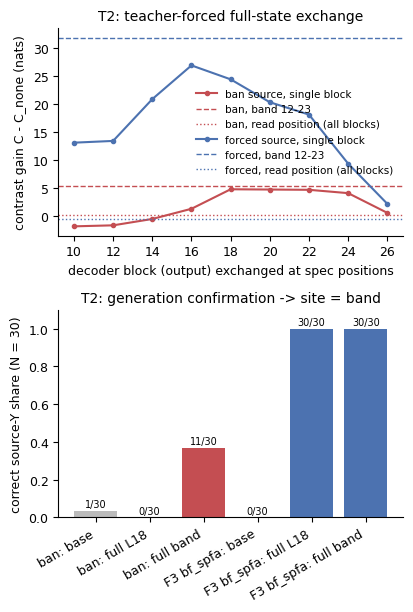

In [11]:
site, ks, T = read_json(results7("site_T2.json")), read_json(results7("kstar_T2.json")), read_json(results7("targets_T2.json"))
print("Stage 0, forced 'Implement Y' (correct Y of 20):", {Y: a["correct_Y"] for Y, a in T["adherence"].items()})
print("kept Y:", T["kept_Y"], "| ban landing set:", T["landing"], "| default:", T["default"])
print("L* =", site["L_star"], "| site =", site["site"], "| k* =", ks["k_star"], "| forced cells:", ks["kept_Y_cells"])
print("committed contrastive map (MAIN): best validation gain",
      round(meta["das_fits_T2"]["F3_check"]["best_val_mean_gain"], 1), "nats -> diverged")
print("amended LME_Y map (MAIN_LY):       best validation gain",
      round(meta["das_fits_ly_T2"]["fits"]["MAIN_LY"]["best_val"], 2), "nats")
f1(TASKS)  # F1: teacher-forced layer profile + generation confirmation (saved results)

## 6. Report stage: `src/analysis7.py`

This is the artifact's analysis code, committed before any held-out generation was scored. Its definitions:
- `correct-Y(row)`: the program passed the hidden tests **and** its mechanism label is in Y(source).
- `TRANSFER(arm)` = (correct-Y count under the arm − the count under the unedited base) / N, on the paired CRN
  slots 0-29.
- `RECOVERY_k` = Σ over held-out sources of [count(DAS_k) − count(base)] / Σ of [count(FULL) − count(base)].

DAS *recovers* the full-state transfer when RECOVERY_k ≈ 1 at a small rank k. The first block below is the data
access and the pooled statistics, copied as they are. Only `BOOT` moves to the config cell.

In [12]:
N = 30
# BOOT = 2000  # notebook: set in the config cell


# ------------------------------------------------------------------------------------------------ data
def arms_of(task: str) -> dict[str, dict[int, dict[str, Any]]]:
    out: dict[str, dict[int, dict[str, Any]]] = defaultdict(dict)
    for r in read_jsonl(LABELS7):
        if r["task"] == task:
            out[r["arm"]][int(r["slot_index"])] = r
    return out


def cy(r: dict[str, Any] | None, Y: list[str]) -> int:
    return int(bool(r) and bool(r.get("passed")) and r.get("label") in Y)


def off_default(r: dict[str, Any] | None, D: str) -> int:
    return int(bool(r) and bool(r.get("passed")) and r.get("label") not in (D, "invalid", None))


def vec(A: dict, arm: str, Y: list[str], n: int = N) -> np.ndarray | None:
    if arm not in A:
        return None
    return np.array([cy(A[arm].get(s), Y) for s in range(n)])


def pass_rate(A: dict, arm: str, n: int = N) -> float | None:
    if arm not in A:
        return None
    rs = [A[arm].get(s) for s in range(n) if A[arm].get(s)]
    return float(np.mean([bool(r.get("passed")) for r in rs])) if rs else None


def full_ban_arm(task: str) -> str:
    s = read_json(results7(f"site_{task}.json"))
    return "FULL_ban_band" if s["site"] == "band" else f"FULL_ban_L{s['L_star']}"


# ------------------------------------------------------------------------------------------------ sources
PREFIX = {"MAIN": ("DAS", "PERM", "PERM", "RPOS", "REV", "NULL"),
          "MAIN_LY": ("DASLY", "PERMLY", "PERM_LY", "RPOSLY", "REVLY", "NULLLY")}
FIT = {"name": "MAIN_LY"}


def sources(task: str) -> list[dict[str, Any]]:
    """Held-out sources with their arm names, base arm and Y set (map FIT['name'])."""
    P, PP = PREFIX[FIT["name"]][:2]
    T = read_json(results7(f"targets_{task}.json"))
    ks = read_json(results7(f"kstar_{task}.json"))
    landing = T["landing"] or T["kept_Y"][:1]
    out = [{"name": "ban", "Y": landing, "base": "BASE_W5", "full": full_ban_arm(task),
            "das": {k: f"{P}_ban_k{k}" for k in RANKS},
            "rand": {16: ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"],
                     ks["k_star"]: ([f"RAND_ban_k{ks['k_star']}"] if ks["k_star"] != 16 else
                                    ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"])},
            "perm": {16: f"{PP}_ban_k16", ks["k_star"]: f"{PP}_ban_k{ks['k_star']}"}}]
    for Y in ks["kept_Y_cells"]:
        out.append({"name": f"F_{Y}", "Y": [Y], "base": "BASE_PAD", "full": f"FULL_F_{Y}",
                    "das": {k: f"{P}_F_{Y}_k{k}" for k in (1, 4, 16)}, "rand": {16: [f"RAND_F_{Y}_k16"]},
                    "perm": {16: f"{PP}_F_{Y}_k16"}})
    return out


def counts_vec(A: dict, src: dict[str, Any], arm: str) -> np.ndarray | None:
    return vec(A, arm, src["Y"])


def pooled_recovery(A: dict, srcs: list[dict[str, Any]], k: int, slots: np.ndarray | None = None,
                    which: str = "das") -> tuple[float | None, float, float]:
    num = den = 0.0
    for s in srcs:
        b, f = counts_vec(A, s, s["base"]), counts_vec(A, s, s["full"])
        if which == "das":
            arms = [s["das"].get(k)] if s["das"].get(k) else []
        else:
            arms = s["rand"].get(k, [])
        vs = [counts_vec(A, s, a) for a in arms]
        vs = [v for v in vs if v is not None]
        if b is None or f is None or not vs:
            continue
        idx = slots if slots is not None else np.arange(N)
        x = float(np.mean([v[idx].sum() for v in vs]))
        num += x - b[idx].sum()
        den += f[idx].sum() - b[idx].sum()
    return (num / den if den > 0 else None), num, den


def boot_ci(A: dict, srcs: list[dict[str, Any]], k: int, which: str = "das", seed: int = 20261022
            ) -> list[float | None]:
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(BOOT):
        idx = rng.integers(0, N, N)
        r, _, _ = pooled_recovery(A, srcs, k, idx, which)
        if r is not None:
            vals.append(r)
    if len(vals) < 100:
        return [None, None]
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]


def mcnemar_das_rand(A: dict, srcs: list[dict[str, Any]], k: int) -> dict[str, Any]:
    b = c = 0
    for s in srcs:
        da = s["das"].get(k)
        ra = (s["rand"].get(k) or [None])[0]
        if not da or not ra or da not in A or ra not in A:
            continue
        v1, v2 = counts_vec(A, s, da), counts_vec(A, s, ra)
        b += int(((v1 == 1) & (v2 == 0)).sum())
        c += int(((v1 == 0) & (v2 == 1)).sum())
    return {"b_das_only": b, "c_rand_only": c, "p": mcnemar_exact(b, c)}

### 6a. P1: does a rank-k DAS subspace recover the full-state transfer in generation?

`p1_task` counts correct-Y programs per arm for every held-out source: the **W5 ban** (landing: Bellman-Ford/SPFA)
and the forced **Floyd-Warshall** source (template families 3-4). From these counts it computes transfer, recovery,
Clopper-Pearson intervals, the slot-cluster bootstrap, and the exact McNemar test of DAS against a random rank-k
subspace on the same slots.

`p1_all` then applies the committed clauses:
- recovery ≥ 0.8;
- margin over random ≥ 0.4;
- permuted-label transfer ≤ 0.1;
- pass rate ≥ 0.8 × base;
- McNemar Holm p < 0.01;
- on T2 only, a random-init network ratio < 0.5.

*Demo subset:* the forced Bellman-Ford/SPFA source is not shipped, so it is skipped. The per-source counts below
match the full run exactly. The pooled rank-1/4/16 recoveries pool fewer sources than the full run did. For
example, rank-16 recovery is 1.67 over the ban and Floyd-Warshall sources, against 0.73 over all three in the full
run. So `p1_all` may evaluate P1 at k = 16 here instead of the full run's k* = 2. The verdict is the same, FAIL,
because the permuted-label clause fails at either rank.

In [13]:
# ------------------------------------------------------------------------------------------------ P1
def p1_task(task: str) -> dict[str, Any]:
    A = arms_of(task)
    srcs = sources(task)
    ks = read_json(results7(f"kstar_{task}.json"))["k_star"]
    out: dict[str, Any] = {"task": task, "k_star": ks, "per_k": {}, "per_source": {}}
    for s in srcs:
        b, f = counts_vec(A, s, s["base"]), counts_vec(A, s, s["full"])
        if b is None or f is None:
            continue
        ps = {"Y": s["Y"], "base_count": int(b.sum()), "full_count": int(f.sum()),
              "full_transfer": float((f.sum() - b.sum()) / N), "base_pass": pass_rate(A, s["base"]),
              "full_pass": pass_rate(A, s["full"]), "das": {}, "rand": {}, "perm": {}}
        for k, a in s["das"].items():
            v = counts_vec(A, s, a)
            if v is not None:
                ps["das"][k] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                "recovery": float((v.sum() - b.sum()) / (f.sum() - b.sum())) if f.sum() > b.sum()
                                else None, "pass": pass_rate(A, a),
                                "share_ci": clopper_pearson(int(v.sum()), N)}
        for k, arms in s["rand"].items():
            for a in arms:
                v = counts_vec(A, s, a)
                if v is not None:
                    ps["rand"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                     "pass": pass_rate(A, a)}
        for k, a in s["perm"].items():
            v = counts_vec(A, s, a)
            if v is not None:
                ps["perm"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                 "pass": pass_rate(A, a)}
        out["per_source"][s["name"]] = ps
    cand_k = sorted({16, ks})
    for k in RANKS:
        r, num, den = pooled_recovery(A, srcs, k)
        rr, rnum, rden = pooled_recovery(A, srcs, k, which="rand") if k in cand_k else (None, 0, 0)
        e = {"recovery": r, "num": num, "den": den, "recovery_ci": boot_ci(A, srcs, k) if r is not None else None,
             "random_recovery": rr}
        if k in cand_k:
            e["mcnemar_das_vs_rand"] = mcnemar_das_rand(A, srcs, k)
            perm_tr = []
            for s in srcs:
                a = s["perm"].get(k)
                b = counts_vec(A, s, s["base"])
                v = counts_vec(A, s, a) if a else None
                if v is not None and b is not None:
                    perm_tr.append(float((v.sum() - b.sum()) / N))
            e["permuted_transfer_max"] = max(perm_tr) if perm_tr else None
            # pass clause on every DAS arm at k
            pr = []
            for s in srcs:
                a = s["das"].get(k)
                if a and a in A and pass_rate(A, s["base"]):
                    pr.append(pass_rate(A, a) / pass_rate(A, s["base"]))
            e["pass_ratio_min"] = min(pr) if pr else None
        out["per_k"][k] = e
    # slot IIA for the ban source (label equals the full ban prompt's label on the slot)
    ref = A.get("BAN_W5", {})
    iia = {}
    for k in RANKS:
        a = f"{PREFIX[FIT['name']][0]}_ban_k{k}"
        if a in A and ref:
            iia[k] = float(np.mean([A[a][s]["label"] == ref[s]["label"] for s in range(N) if s in A[a] and s in ref]))
    fa = full_ban_arm(task)
    if fa in A and ref:
        iia["full"] = float(np.mean([A[fa][s]["label"] == ref[s]["label"] for s in range(N) if s in A[fa] and s in ref]))
    out["slot_iia_ban"] = iia
    return out


def p1_all(tasks: list[str]) -> dict[str, Any]:
    res = {t: p1_task(t) for t in tasks}
    # choose per task the candidate k (16 or k*) that satisfies the most clauses (smallest p on ties)
    pv = {}
    for t, r in res.items():
        best = None
        for k in sorted({16, r["k_star"]}):
            e = r["per_k"][k]
            if e.get("mcnemar_das_vs_rand") is None:
                continue
            cl = {"recovery_ge_0.8": (e["recovery"] or 0) >= 0.8,
                  "margin_ge_0.4": (e["recovery"] or 0) - (e["random_recovery"] or 0) >= 0.4,
                  "permuted_le_0.1": e["permuted_transfer_max"] is not None and e["permuted_transfer_max"] <= 0.1,
                  "pass_ge_0.8x": e["pass_ratio_min"] is not None and e["pass_ratio_min"] >= 0.8}
            score = (sum(cl.values()), -e["mcnemar_das_vs_rand"]["p"])
            if best is None or score > best[0]:
                best = (score, k, cl)
        if best:
            r["P1_k"] = best[1]
            r["P1_clauses"] = best[2]
            pv[t] = r["per_k"][best[1]]["mcnemar_das_vs_rand"]["p"]
    ph = holm(pv)
    n_pass = 0
    for t, r in res.items():
        if "P1_k" not in r:
            r["P1"] = "NOT ESTIMABLE"
            continue
        r["P1_clauses"]["mcnemar_holm_lt_0.01"] = ph.get(t, 1.0) < 0.01
        r["mcnemar_p_holm"] = ph.get(t)
        # the Sutter control matched to the evaluated map: the LME_Y-objective random-network fit when present
        rp = results7(f"randinit_ly_{t}.json") if FIT["name"] == "MAIN_LY" else results7(f"randinit_{t}.json")
        ri = read_json(rp) if rp.exists() else None
        r["random_init_control"] = {"file": rp.name, "present": ri is not None,
                                    **({k: ri.get(k) for k in ("random_net_heldout_das16_gain",
                                                              "trained_heldout_das16_gain", "ratio",
                                                              "random_net_heldout_das16_lmeY_gain",
                                                              "trained_heldout_das16_lmeY_gain", "ratio_lmeY")}
                                       if ri else {})}
        if t == "T2":
            r["P1_clauses"]["random_init_lt_0.5"] = bool(ri and ri.get("c3_pass_lt_0.5"))
        ok = all(r["P1_clauses"].values())
        r["P1"] = "PASS" if ok else "FAIL"
        n_pass += ok
    rec16 = [r["per_k"][16]["recovery"] for r in res.values() if r["per_k"].get(16)]
    overall = ("PASS" if n_pass >= 2 else ("DISCONFIRMED" if rec16 and all((x or 0) < 0.5 for x in rec16)
                                            else "NOT SUPPORTED"))
    return {"tasks": res, "holm": ph, "n_pass": n_pass, "overall": overall}

In [14]:
FIT["name"] = "MAIN_LY"                                               # report7.py: the amended LME_Y map
tasks = [t for t in TASKS if results7(f"kstar_{t}.json").exists()]   # report7.py
t0 = time.time()
p1 = p1_all(tasks)
write_json(results7("p1.json"), p1)
print(f"p1_all({tasks}) in {time.time() - t0:.1f} s (BOOT = {BOOT})")

r, saved = p1["tasks"]["T2"], meta["p1"]["tasks"]["T2"]
tab = []
for name, ps in r["per_source"].items():
    sv = saved["per_source"][name]
    tab.append({"source": name, "arm": "base (unedited)", "correct Y / 30": ps["base_count"],
                "full run": sv["base_count"], "transfer": 0.0, "pass": ps["base_pass"]})
    tab.append({"source": name, "arm": "FULL (full-state, ceiling)", "correct Y / 30": ps["full_count"],
                "full run": sv["full_count"], "transfer": ps["full_transfer"], "pass": ps["full_pass"]})
    for k, e in ps["das"].items():
        tab.append({"source": name, "arm": f"DAS rank {k}", "correct Y / 30": e["count"],
                    "full run": sv["das"][str(k)]["count"], "transfer": e["transfer"], "pass": e["pass"]})
    for grp in ("rand", "perm"):
        for a, e in ps[grp].items():
            tab.append({"source": name, "arm": a, "correct Y / 30": e["count"], "full run": sv[grp][a]["count"],
                        "transfer": e["transfer"], "pass": e["pass"]})
display(pd.DataFrame(tab))

for k, e in r["per_k"].items():
    mc = e.get("mcnemar_das_vs_rand")
    print(f"k={k:>2}: recovery {fmt(e['recovery'])} CI {[fmt(x) for x in (e['recovery_ci'] or [None, None])]}"
          + (f" | random {fmt(e['random_recovery'])} | McNemar DAS vs random {mc['b_das_only']}:{mc['c_rand_only']} "
             f"p={mc['p']:.2g} | permuted max {fmt(e['permuted_transfer_max'])} | pass ratio {fmt(e['pass_ratio_min'])}"
             if mc else ""))
print(f"\nP1 (T2) = {r['P1']} at k = {r['P1_k']}; clauses: {r['P1_clauses']}")
print(f"full run: P1 (T2) = {saved['P1']} at k = {saved['P1_k']}; P1 over T2, T10, T03 = {meta['p1']['overall']}")

p1_all(['T2']) in 0.6 s (BOOT = 2000)


,source,arm,correct Y / 30,full run,transfer,pass
0,ban,base (unedited),1,1,0.000,0.967
1,ban,"FULL (full-state, ceiling)",11,11,0.333,0.733
2,ban,DAS rank 1,8,8,0.233,0.767
3,ban,DAS rank 2,12,12,0.367,0.833
4,ban,DAS rank 4,10,10,0.300,0.567
5,ban,DAS rank 8,10,10,0.300,0.833
6,ban,DAS rank 16,6,6,0.167,0.800
7,ban,RAND_ban_k16_d1,1,1,0.000,0.967
8,ban,RAND_ban_k16_d2,0,0,-0.033,0.967
9,ban,RAND_ban_k16_d3,1,1,0.000,0.967


k= 1: recovery 1.94 CI ['1.32', '3.18']
k= 2: recovery 1.10 CI ['0.53', '2.43'] | random 0.00 | McNemar DAS vs random 11:0 p=0.00098 | permuted max 0.47 | pass ratio 0.86
k= 4: recovery 2.06 CI ['1.39', '3.42']
k= 8: recovery 0.90 CI ['0.36', '2.00']
k=16: recovery 1.67 CI ['1.12', '2.79'] | random -0.02 | McNemar DAS vs random 31:1 p=1.5e-08 | permuted max 0.20 | pass ratio 0.83

P1 (T2) = FAIL at k = 16; clauses: {'recovery_ge_0.8': np.True_, 'margin_ge_0.4': np.True_, 'permuted_le_0.1': False, 'pass_ge_0.8x': True, 'mcnemar_holm_lt_0.01': True, 'random_init_lt_0.5': False}
full run: P1 (T2) = FAIL at k = 2; P1 over T2, T10, T03 = NOT SUPPORTED


### 6b. Specificity controls

`controls` tests whether other edits also move the ban to Bellman-Ford/SPFA:
- a read-position DAS map, which edits at the last prompt token instead of the spec;
- the read-position full-state exchange;
- the top difference-in-means direction (DIM-1);
- the top-16 PCA subspace.

The held-out W4 ban (N = 10) is reported separately. The null-source rows (*Implement Dijkstra*) are not in the
subset.

In [15]:
# ------------------------------------------------------------------------------------------------ controls
def controls(task: str) -> dict[str, Any]:
    A = arms_of(task)
    T = read_json(results7(f"targets_{task}.json"))
    D = DEFAULT7[task]
    landing = T["landing"] or T["kept_Y"][:1]
    out = {}

    def tr(arm: str, base: str, Y: list[str]) -> dict[str, Any] | None:
        v, b = vec(A, arm, Y), vec(A, base, Y)
        if v is None or b is None:
            return None
        return {"count": int(v.sum()), "base": int(b.sum()), "transfer": float((v.sum() - b.sum()) / N),
                "pass": pass_rate(A, arm), "n": int(len(A[arm]))}
    for arm in ("RPOSLY_ban_k16", "RPOS_ban_k16", "RPOSFULL_ban", "DIM1_ban", "PCA16_ban"):
        out[arm] = tr(arm, "BASE_W5", landing)
    # null source: off-default transfer against the padding-twin base of the same prompts
    for arm in ("NULLLY_k16", "NULL_k16", "NULL_full"):
        if arm in A and "BASE_PAD" in A:
            v = np.array([off_default(A[arm].get(s), D) for s in range(N)])
            b = np.array([off_default(A["BASE_PAD"].get(s), D) for s in range(N)])
            out[arm] = {"off_default_count": int(v.sum()), "base_off_default": int(b.sum()),
                        "off_default_transfer": float((v.sum() - b.sum()) / N), "pass": pass_rate(A, arm),
                        "labels": dict(Counter(A[arm][s]["label"] for s in A[arm]))}
    # W4 reported separately (N = 10)
    ks = read_json(results7(f"kstar_{task}.json"))["k_star"]
    for arm in ("BASE_W4", "FULL_W4", f"{PREFIX[FIT['name']][0]}_W4_k{ks}"):
        if arm in A:
            v = np.array([cy(A[arm].get(s), landing) for s in range(10)])
            out[arm] = {"count": int(v.sum()), "n": 10, "pass": pass_rate(A, arm, 10)}
    return out



ctrl = {t: controls(t) for t in tasks}
for t, c in ctrl.items():
    write_json(results7(f"p1_controls_{t}.json"), c)
saved_c = meta["p1_controls_T2"]
display(pd.DataFrame([{"arm": a, **e, "full run count": (saved_c.get(a) or {}).get("count")}
                      for a, e in ctrl["T2"].items() if e]))

,arm,count,base,transfer,pass,n,full run count
0,RPOSLY_ban_k16,2,1.0,0.033,0.900,30,2
1,RPOSFULL_ban,1,1.0,0.000,0.967,30,1
2,DIM1_ban,0,1.0,-0.033,0.967,30,0
3,PCA16_ban,1,1.0,0.000,0.833,30,1
4,BASE_W4,0,NaN,NaN,1.000,10,0
5,FULL_W4,4,NaN,NaN,0.500,10,4
6,DASLY_W4_k2,4,NaN,NaN,0.900,10,4


### 6c. C (routing): can the map write one *specific* non-default algorithm?

For a forced source *Implement Y*, routing = (correct programs that are Y) / (correct programs that are
off-default). Here Y is Floyd-Warshall:
- **Full-state exchange.** The band exchange makes the model leave Dijkstra on 20 slots, but only 8 of those
  programs are Floyd-Warshall; the other 12 are Bellman-Ford.
- **Rank-1 DAS map.** It routes every correct off-default program to Floyd-Warshall (28/28).

So the map writes the forced algorithm *more* strongly than the source's own states transfer it. The cross-task
verdict (`c_verdict`, CATEGORICAL by rule on T2 and T03) needs all three tasks and the forced Bellman-Ford source,
so it is printed from the saved results.

In [16]:
def routing(task: str, p1k: int | None) -> dict[str, Any]:
    A = arms_of(task)
    D = DEFAULT7[task]
    ks = read_json(results7(f"kstar_{task}.json"))
    out = {"task": task, "per_Y": {}, "confusion": {}}
    labs = CATALOGUE7[task] + ["other"]
    for Y in ks["kept_Y_cells"]:
        e = {}
        for nm, arm in [("full", f"FULL_F_{Y}")] + [(f"k{k}", f"{PREFIX[FIT['name']][0]}_F_{Y}_k{k}")
                                                    for k in (1, 4, 16)]:
            if arm not in A:
                continue
            rs = [A[arm][s] for s in range(N) if s in A[arm]]
            corr = [r for r in rs if r.get("passed")]
            offd = [r for r in corr if r["label"] != D]
            ny = sum(r["label"] == Y for r in corr)
            rt = ny / len(offd) if offd else None
            e[nm] = {"n": len(rs), "correct_Y": ny, "correct_off_default": len(offd),
                     "routing": rt, "routing_ci": clopper_pearson(ny, len(offd)) if offd else None,
                     "off_default_transfer": len(offd) / N,
                     "landing": dict(Counter(r["label"] for r in corr)), "fail": len(rs) - len(corr)}
            out["confusion"].setdefault(nm, {})[Y] = {l: sum(r["label"] == l for r in corr) for l in labs}
            out["confusion"][nm][Y]["fail"] = len(rs) - len(corr)
        e["routable_at_site"] = (e.get("full", {}).get("routing") or 0) >= 0.6
        out["per_Y"][Y] = e
    kk = p1k if p1k in (1, 4, 16) else 16
    out["k_for_C"] = kk
    cat_Y = [Y for Y, e in out["per_Y"].items() if (e.get(f"k{kk}", {}).get("routing") or 0) >= 0.6]
    out["Y_routed_ge_0.6"] = cat_Y
    small = None
    for k in (1, 4, 16):
        if sum((e.get(f"k{k}", {}).get("routing") or 0) >= 0.6 for e in out["per_Y"].values()) >= 2:
            small = k
            break
    out["smallest_k_routing_2Y"] = small
    return out



rt = {t: routing(t, p1["tasks"][t].get("P1_k")) for t in tasks}
fl, fl_s = rt["T2"]["per_Y"]["floyd"], meta["c_routing"]["per_task"]["T2"]["per_Y"]["floyd"]
display(pd.DataFrame([{"arm": nm, "correct Floyd-Warshall": e["correct_Y"], "correct off-default": e["correct_off_default"],
                       "routing": e["routing"], "correct programs by label": e["landing"], "failed": e["fail"],
                       "full run": f"{fl_s[nm]['correct_Y']}/{fl_s[nm]['correct_off_default']}"}
                      for nm, e in fl.items() if isinstance(e, dict)]))
print("routable at the site by the full-state exchange (routing >= 0.6):", fl["routable_at_site"])
print("saved cross-task verdict:", meta["c_routing"]["verdict"])

,arm,correct Floyd-Warshall,correct off-default,routing,correct programs by label,failed,full run
0,full,8,20,0.4,"{'bf_spfa': 12, 'floyd': 8}",10,8/20
1,k1,28,28,1.0,{'floyd': 28},2,28/28
2,k4,28,28,1.0,{'floyd': 28},2,28/28
3,k16,25,25,1.0,{'floyd': 25},5,25/25


routable at the site by the full-state exchange (routing >= 0.6): False
saved cross-task verdict: {'verdict': 'CATEGORICAL', 'categorical_tasks': ['T2', 'T03'], 'margin_and_ladder_by_task': {'T2': False, 'T10': False, 'T03': False}}


### 6d. R: is the algorithm choice a discrete switch?

`r_discreteness` fits a logistic curve to correct-Bellman-Ford outcomes along a λ-scaled rank-2 edit, and reads its
10-90 % width. DISCRETE needs a width ≤ 0.3. The λ-sweep rows (`LAM*_ban_k2`, N = 20 × 10) are not in the subset,
so `r_discreteness` returns `None` here. The saved sweep keeps the per-λ counts, which is all the original
`logistic_width` needs, so the fit is redone from them.

In [17]:
def logistic_width(lams: np.ndarray, y: np.ndarray) -> dict[str, Any]:
    from scipy.optimize import minimize

    def nll(th: np.ndarray) -> float:
        l0, ls = th
        s = math.exp(ls)
        p = 1 / (1 + np.exp(-(lams - l0) / s))
        p = np.clip(p, 1e-9, 1 - 1e-9)
        return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).sum())
    best = None
    for l0 in (0.3, 0.6, 0.9, 1.2):
        for ls in (-3.0, -2.0, -1.0, 0.0):
            r = minimize(nll, np.array([l0, ls]), method="Nelder-Mead", options={"xatol": 1e-5, "fatol": 1e-7,
                                                                                  "maxiter": 4000})
            if best is None or r.fun < best.fun:
                best = r
    l0, ls = best.x
    s = math.exp(ls)
    return {"lam0": float(l0), "s": float(s), "width_10_90": float(2 * s * math.log(9)), "nll": float(best.fun)}


def r_discreteness(task: str) -> dict[str, Any] | None:
    A = arms_of(task)
    T = read_json(results7(f"targets_{task}.json"))
    landing = T["landing"] or T["kept_Y"][:1]
    D = DEFAULT7[task]
    rows = []
    for arm, d in A.items():
        if arm.startswith("LAM") and "_ban_" in arm:
            lam = float(arm[3:].split("_")[0])
            for s, r in d.items():
                rows.append((lam, cy(r, landing), r))
    if not rows:
        return None
    lams = np.array([x[0] for x in rows])
    y = np.array([x[1] for x in rows])
    fit = logistic_width(lams, y)
    curve = {}
    for lam in sorted(set(lams)):
        rs = [x[2] for x in rows if x[0] == lam]
        curve[lam] = {"n": len(rs), "correct_Y": int(sum(cy(r, landing) for r in rs)),
                      "correct_default": int(sum(cy(r, [D]) for r in rs)),
                      "pass": float(np.mean([bool(r.get("passed")) for r in rs])),
                      "labels": dict(Counter(r["label"] for r in rs))}
    cand = [x[2] for x in rows if 0.2 <= x[0] <= 1.0 and x[2].get("passed") and
            (x[2]["label"] == "other" or (x[2].get("runtime_label") not in (None, x[2].get("ast_label"))
                                          and x[2].get("ast_label") not in (None, "unknown")))]
    n_correct = int(sum(bool(x[2].get("passed")) for x in rows if 0.2 <= x[0] <= 1.0))
    return {"task": task, "fit": fit, "curve": curve, "hybrid_candidates": [r["sample_id"] for r in cand],
            "n_correct_0.2_1.0": n_correct}



rr = r_discreteness("T2")  # report7.py
print("r_discreteness on the demo rows:", rr)
rr_saved = meta["r_discreteness"]
lams = np.array([float(l) for l, v in rr_saved["curve"].items() for _ in range(v["n"])])
y = np.array([int(i < v["correct_Y"]) for v in rr_saved["curve"].values() for i in range(v["n"])])
fit = logistic_width(lams, y)
print("correct Bellman-Ford per lambda:", {l: f"{v['correct_Y']}/{v['n']}" for l, v in rr_saved["curve"].items()})
print(f"refitted: lam0 {fit['lam0']:.2f}, 10-90% width {fit['width_10_90']:.2f} | full run: width "
      f"{rr_saved['fit']['width_10_90']:.2f} -> graded, not discrete")

r_discreteness on the demo rows: None
correct Bellman-Ford per lambda: {'0.0': '1/20', '0.2': '1/20', '0.4': '4/20', '0.5': '4/20', '0.6': '6/20', '0.7': '8/20', '0.8': '7/20', '1.0': '9/20', '1.25': '7/20', '1.5': '8/20'}
refitted: lam0 1.47, 10-90% width 3.25 | full run: width 3.25 -> graded, not discrete


### 6e. The committed map, seeds and instructions, and a second init seed

- **`pilot_main`.** The committed contrastive map (`DAS_*` arms, the objective that diverged in fitting) on slots
  0-9. It writes broken programs.
- **`mgen_summary`.** What the prompts placed by M make the model **write**, N = 30 each: the bare spec (`p0`), two
  random seeds, a semantic seed, *"Make a new algorithm."* and the 2,000-word novelty instruction. This is the
  behavioural answer to *can a context seed or an instruction move the model off its default?*
- **`seed2_summary`.** A second DAS init seed finds a different subspace (principal angles of 38-90°) that behaves
  alike.

In [18]:
def pilot_main(task: str) -> dict[str, Any]:
    """The committed contrastive map (MAIN) on slots 0-9: correct-Y, pass rate, label mix, mean length per arm."""
    A = arms_of(task)
    T = read_json(results7(f"targets_{task}.json"))
    landing = T["landing"] or T["kept_Y"][:1]
    out = {}
    for arm in sorted(a for a in A if a.startswith("DAS_")):
        Y = landing if "_ban_" in arm else [arm.split("_F_")[1].rsplit("_k", 1)[0]]
        rs = [A[arm][s] for s in range(10) if s in A[arm]]
        base = "BASE_W5" if "_ban_" in arm else "BASE_PAD"
        b = [A[base][s] for s in range(10) if base in A and s in A[base]]
        out[arm] = {"n": len(rs), "correct_Y": sum(cy(r, Y) for r in rs), "base_correct_Y": sum(cy(r, Y) for r in b),
                    "pass": float(np.mean([bool(r.get("passed")) for r in rs])) if rs else None,
                    "base_pass": float(np.mean([bool(r.get("passed")) for r in b])) if b else None,
                    "labels": dict(Counter(r["label"] for r in rs)),
                    "mean_new_tokens": float(np.mean([r.get("n_new_tokens") or 0 for r in rs])) if rs else None,
                    "finish": dict(Counter(r.get("finish_reason") for r in rs))}
    return out


def mgen_summary(task: str = "T2") -> dict[str, Any] | None:
    """Behaviour of the prompts M places (extension): correct label composition per prompt kind, N = 30."""
    A = arms_of(task)
    D = DEFAULT7[task]
    out = {}
    for arm in sorted(a for a in A if a.startswith("MGEN_")):
        rs = [A[arm][s] for s in range(N) if s in A[arm]]
        corr = Counter(r["label"] for r in rs if r.get("passed"))
        off = sum(v for k, v in corr.items() if k not in (D,))
        out[arm[5:]] = {"n": len(rs), "pass": float(np.mean([bool(r.get("passed")) for r in rs])) if rs else None,
                        "correct_composition": dict(corr), "correct_off_default": off,
                        "off_default_ci": clopper_pearson(off, len(rs)) if rs else None,
                        "n_truncated": sum(r.get("finish_reason") == "length" for r in rs)}
    return out or None


def seed2_summary(task: str = "T2") -> dict[str, Any] | None:
    rj = read_json  # notebook: cfg.read_json is defined above (original: from cfg import read_json as rj)
    p = results7(f"seed2_{task}.json")
    if not p.exists():
        return None
    s2 = rj(p)
    A = arms_of(task)
    T = read_json(results7(f"targets_{task}.json"))
    landing = T["landing"] or T["kept_Y"][:1]
    rows = {}
    for arm in sorted(a for a in A if a.startswith("DASLY2_")):
        Y = landing if "_ban_" in arm else [arm.split("_F_")[1].rsplit("_k", 1)[0]]
        a1 = arm.replace("DASLY2_", "DASLY_")
        v2, v1 = vec(A, arm, Y), vec(A, a1, Y)
        e = {"seed2_count": int(v2.sum()) if v2 is not None else None,
             "seed1_count": int(v1.sum()) if v1 is not None else None, "pass_seed2": pass_rate(A, arm)}
        if v1 is not None and v2 is not None:
            e["discordant_s1only_s2only"] = [int(((v1 == 1) & (v2 == 0)).sum()), int(((v1 == 0) & (v2 == 1)).sum())]
            e["mcnemar_p"] = mcnemar_exact(*e["discordant_s1only_s2only"])
        rows[arm] = e
    return {"task": task, "principal_angles_deg": s2["principal_angles_deg"], "cells": rows,
            "fit_best_val": s2["fit"].get("best_val")}



core = [t for t in tasks if t in ("T2", "T10")]                     # report7.py
pilot = {t: pilot_main(t) for t in core}
write_json(results7("committed_map_pilot.json"), pilot)
display(pd.DataFrame([{"committed-map arm (slots 0-9)": a, **{k: e[k] for k in ("correct_Y", "base_correct_Y", "pass",
                       "base_pass", "labels", "finish")}} for a, e in pilot["T2"].items()]))

mg = mgen_summary("T2")
write_json(results7("m_behaviour.json"), mg)
seg = {p["kind"]: p["segment"] for p in read_jsonl(PROMPTS7)}
mb_s = extra["m_behaviour"]
display(pd.DataFrame([{"prompt kind": k, "text before the task": seg.get(k, "")[:70] or "(none: bare spec)",
                       "correct programs by label (N = 30)": e["correct_composition"],
                       "correct off-default": e["correct_off_default"], "pass": e["pass"],
                       "full run": mb_s[k]["correct_composition"]} for k, e in mg.items()]))

s2 = seed2_summary("T2")
write_json(results7("seed2_summary.json"), s2)
print("second init seed: principal angles to seed 1 (deg):",
      {k: [round(a) for a in v] for k, v in s2["principal_angles_deg"].items()})
display(pd.DataFrame([{"seed-2 arm": a, **e} for a, e in s2["cells"].items()]))

,committed-map arm (slots 0-9),correct_Y,base_correct_Y,pass,base_pass,labels,finish
0,DAS_F_floyd_k1,0,0,0.5,0.9,"{'other': 4, 'bf_spfa': 1, 'dijkstra': 5}","{'stop': 9, 'fence': 1}"
1,DAS_F_floyd_k16,0,0,0.0,0.9,"{'other': 9, 'dijkstra': 1}",{'length': 10}
2,DAS_F_floyd_k4,0,0,0.0,0.9,"{'dijkstra': 1, 'other': 9}",{'length': 10}
3,DAS_ban_k1,0,1,0.1,0.9,"{'dijkstra': 4, 'other': 6}","{'stop': 4, 'fence': 1, 'length': 5}"
4,DAS_ban_k16,0,1,0.0,0.9,"{'other': 6, 'dijkstra': 4}","{'length': 9, 'fence': 1}"
5,DAS_ban_k2,0,1,0.0,0.9,"{'dijkstra': 6, 'other': 4}","{'length': 7, 'stop': 3}"
6,DAS_ban_k4,0,1,0.0,0.9,"{'other': 9, 'bf_spfa': 1}","{'length': 7, 'fence': 1, 'stop': 2}"
7,DAS_ban_k8,0,1,0.0,0.9,"{'other': 9, 'dijkstra': 1}",{'length': 10}


,prompt kind,text before the task,correct programs by label (N = 30),correct off-default,pass,full run
0,instr_new,Make a new algorithm.,{'dijkstra': 30},0,1.000,{'dijkstra': 30}
1,instr_novel,Make a fully novel algorithm never seen before for this task. Before w,"{'dijkstra': 22, 'bf_spfa': 6}",6,0.933,"{'dijkstra': 22, 'bf_spfa': 6}"
2,p0,(none: bare spec),{'dijkstra': 29},0,0.967,{'dijkstra': 29}
3,seed_rand1,seed=d32qxk4nt43,{'dijkstra': 30},0,1.000,{'dijkstra': 30}
4,seed_rand2,seed=(horse chair roof love),{'dijkstra': 30},0,1.000,{'dijkstra': 30}
5,seed_sem,Here is a programming task. News spreads through a kingdom in rounds.,"{'dijkstra': 28, 'other': 1}",1,0.967,"{'dijkstra': 28, 'other': 1}"


second init seed: principal angles to seed 1 (deg): {'1': [44], '2': [41, 69], '4': [39, 57, 80, 81], '16': [38, 48, 60, 67, 71, 76, 77, 81, 81, 83, 84, 85, 85, 86, 88, 90]}


,seed-2 arm,seed2_count,seed1_count,pass_seed2,discordant_s1only_s2only,mcnemar_p
0,DASLY2_F_floyd_k16,27,25,0.900,"[0, 2]",0.500
1,DASLY2_ban_k1,3,8,0.733,"[6, 1]",0.125
2,DASLY2_ban_k16,7,6,0.667,"[3, 4]",1.000
3,DASLY2_ban_k2,8,12,0.600,"[6, 2]",0.289


## 7. M: where do prompts sit in the plan subspace? (`src/m7.py`)

**The points.** Each prompt becomes one point $z$: the mean over spec positions of the $R_{16}$ coordinates of its
block-18 hidden state. These are real Qwen3-8B activation coordinates, in residual units: 151 prompts × 16
dimensions.
- 60 neutral twins, 25 padding twins and the bare spec (`p0`);
- 25 forced *Implement Y* prompts (5 template families × 5 algorithms);
- 5 bans and 20 sham bans;
- 10 leave-one-survivor multi-name bans;
- 2 random seeds, 1 semantic seed and 2 instructions.

**The analysis.**
- **Mean-answer test.** Does a prompt leave the *paraphrase null*, the cloud of 66 prompts that all mean "just
  solve the task"? It uses $D = \lVert z - \bar z_{default} \rVert$, the percentile of $D$ within the null, and the
  signed coordinate along the axis from the Dijkstra (default) centroid to the Bellman-Ford (runner-up) centroid.
- **Geometry.** Metric MDS (stress-1) and Isomap / kNN-graph geodesics of the 16-d points.
- **Top-k placement.** Is a ban that leaves exactly one algorithm allowed placed toward that survivor?

**Changes from the original.** `load_points` changes in one line: the 151 × 4096 spec-mean states are not shipped,
and `analyse` does not use them. The implemented counts come from the saved results (see §3). The MDS restarts,
Isomap kNN, geodesic kNN set and null draws come from the config cell.

**One expected difference.** Every M number below matches the full run except metric-MDS stress-1: 0.084 here
against 0.079. That gap comes from the library version. Colab's scikit-learn 1.6.1 gives 0.084 on these exact
points, while the run's scikit-learn 1.9.1 gives 0.079. So the MDS panel of F4 can look slightly different from the
paper's.

In [19]:
# extracts copied into inputs/ at run time (T2 rows of exp24's Qwen3-8B-Base samples and exp29's random-direction
# labels; exp9's leave-one-survivor behaviour table)
EXP9_LOS = ROOT / "inputs" / "exp9_los.json"


def implemented_counts(task: str) -> dict[str, dict[str, int]]:
    cat = CATALOGUE7[task]
    out = {}
    tw = [r for r in read_jsonl(LABELS7) if r["task"] == task and r["arm"] == "TWIN" and r.get("passed")]
    out["twin"] = {a: sum(r["label"] == a for r in tw) for a in cat}
    inp = ROOT / "inputs" / "exp24_T2_base_samples.jsonl"
    rows = read_jsonl(inp) if inp.exists() else []
    b = [r for r in rows if r["task"] == task and r["arm"] == "BASE_CHAT" and r.get("passed")]
    out["base_model"] = {a: sum(r["label"] == a for r in b) for a in cat}
    knobs = [r for r in read_jsonl(LABELS7) if r["task"] == task and r.get("stage") in ("gen", "r") and r.get("passed")
             and not str(r["arm"]).startswith(("BASE", "PADBASE"))]
    inp29 = ROOT / "inputs" / "exp29_T2_labels.jsonl"
    k29 = [r for r in read_jsonl(inp29) if r["task"] == task and r.get("passed")] if inp29.exists() else []
    out["knobs"] = {a: sum(r["label"] == a for r in knobs) + sum(r["label"] == a for r in k29) for a in cat}
    out["knobs_this_artifact"] = {a: sum(r["label"] == a for r in knobs) for a in cat}
    out["knobs_exp29_random_directions"] = {a: sum(r["label"] == a for r in k29) for a in cat}
    return out


def load_points(task: str) -> tuple[list[str], np.ndarray, np.ndarray]:
    z = np.load(ROOT / "cache" / f"m_states_{task}.npz")
    return [str(k) for k in z["keys"]], z["z"].astype(np.float64), None  # notebook: z["mean"] (151 x 4096) not shipped; unused by analyse()


def geodesic(Z: np.ndarray, k: int) -> np.ndarray:
    from scipy.sparse.csgraph import shortest_path
    from sklearn.neighbors import kneighbors_graph
    G = kneighbors_graph(Z, n_neighbors=k, mode="distance", include_self=False)
    G = G.maximum(G.T)
    return shortest_path(G, method="D", directed=False)


def analyse(task: str = "T2") -> dict[str, Any]:
    from sklearn.manifold import MDS, Isomap
    keys, Z, Mfull = load_points(task)
    kind = [k.split("|")[1] for k in keys]
    meta = {k: r for k, r in ((r["key"], r) for r in read_jsonl(ROOT / "prompts" / "prompts7.jsonl"))}
    D = DEFAULT7[task]
    cat = CATALOGUE7[task]
    idx = {k: i for i, k in enumerate(keys)}
    null_keys = [k for k in keys if meta[k]["kind"] == "twin"] + \
        [k for k in keys if meta[k]["kind"] == "padtwin" and meta[k]["Y"] == D] + \
        [k for k in keys if meta[k]["kind"] == "p0"]
    Zn = Z[[idx[k] for k in null_keys]]
    zbar = Zn.mean(0)
    dnull = np.linalg.norm(Zn - zbar, axis=1)
    cent = {}
    for Y in cat:
        ks = [k for k in keys if meta[k]["kind"] == "forced" and meta[k]["Y"] == Y]
        cent[Y] = Z[[idx[k] for k in ks]].mean(0)
    T = read_json(results7(f"targets_{task}.json"))
    runner = (T["landing"] or T["kept_Y"])[0]
    u = cent[runner] - cent[D]
    u = u / np.linalg.norm(u)
    probes = {}
    for k in keys:
        if meta[k]["kind"] in ("seed_rand1", "seed_rand2", "seed_sem", "instr_new", "instr_novel", "ban", "p0") or \
                (meta[k]["kind"] == "ban" and meta[k]["w"] == "W1"):
            d = float(np.linalg.norm(Z[idx[k]] - zbar))
            probes[k] = {"kind": meta[k]["kind"], "D": d, "null_percentile": float((dnull < d).mean() * 100),
                         "inside_null_95": bool(d <= np.percentile(dnull, 95)),
                         "coord_along_runnerup": float((Z[idx[k]] - zbar) @ u)}
    null_coord = (Zn - zbar) @ u
    # centroid geometry
    cent_coord = {Y: float((cent[Y] - zbar) @ u) for Y in cat}
    # MDS / Isomap of 16-d points
    mds = MDS(n_components=2, n_init=MDS_N_INIT,  # notebook: config (original: 4)
               random_state=0, dissimilarity="euclidean", normalized_stress="auto")
    Y2 = mds.fit_transform(Z)
    from scipy.spatial.distance import pdist, squareform
    Dz = squareform(pdist(Z))
    D2 = squareform(pdist(Y2))
    stress1 = float(np.sqrt(((Dz - D2) ** 2).sum() / (Dz ** 2).sum()))
    iso = Isomap(n_neighbors=ISOMAP_NEIGHBORS, n_components=2).fit_transform(Z)
    geo = {}
    for kk in GEODESIC_KS:  # notebook: config (original: (5, 10, 15))
        G = geodesic(Z, kk)
        tab = {}
        for a in cat:
            ia = [idx[k] for k in keys if meta[k]["kind"] == "forced" and meta[k]["Y"] == a]
            row = {}
            for b in cat:
                ib = [idx[k] for k in keys if meta[k]["kind"] == "forced" and meta[k]["Y"] == b]
                vals = G[np.ix_(ia, ib)]
                row[b] = float(np.nanmean(np.where(np.isfinite(vals), vals, np.nan)))
            tab[a] = row
        # leave-one-survivor placement: rank of the survivor's mean geodesic distance among the 5 algorithms
        place = []
        for k in keys:
            if meta[k]["kind"] != "multiban":
                continue
            dist = {}
            for a in cat:
                ia = [idx[x] for x in keys if meta[x]["kind"] == "forced" and meta[x]["Y"] == a]
                v = G[idx[k], ia]
                dist[a] = float(np.mean(v[np.isfinite(v)])) if np.isfinite(v).any() else float("inf")
            order = sorted(cat, key=lambda a: dist[a])
            place.append({"key": k, "survivor": meta[k]["Y"], "w": meta[k]["w"],
                          "survivor_rank": order.index(meta[k]["Y"]) + 1, "nearest": order[0], "dist": dist})
        ranks = [p["survivor_rank"] for p in place]
        rng = np.random.default_rng(0)
        null = [np.mean(rng.integers(1, len(cat) + 1, len(ranks))) for _ in range(LOS_NULL_DRAWS)]
        geo[kk] = {"centroid_geodesic_table": tab, "los_placement": place,
                   "mean_survivor_rank": float(np.mean(ranks)) if ranks else None,
                   "p_rank_le_observed": float(np.mean(np.array(null) <= np.mean(ranks))) if ranks else None,
                   "n_unreachable": int((~np.isfinite(G)).sum())}
    los = read_json(EXP9_LOS) if EXP9_LOS.exists() else {}
    beh = {s: {"compliant_share": v.get("compliant_share"), "will_attempted_share": v.get("will_attempted_share"),
               "banned_share_by_mechanism": v.get("banned_share_by_mechanism")} for s, v in los.items()}
    # notebook: saved counts (they need all 4,500 labels + exp24/exp29 rows); original: implemented_counts(task)
    counts = read_json(ROOT / "inputs" / f"implemented_counts_{task}.json")
    out = {"task": task, "n_points": len(keys), "zbar_default_norm": float(np.linalg.norm(zbar)),
           "paraphrase_null": {"n": len(null_keys), "D_median": float(np.median(dnull)),
                               "D_95": float(np.percentile(dnull, 95)), "coord_sd": float(np.std(null_coord))},
           "runner_up": runner, "probes": probes, "centroid_coord_along_runnerup": cent_coord,
           "mds_stress1": stress1, "geodesic": geo, "exp9_los_behaviour": beh, "implemented_counts": counts,
           "coords": {"keys": keys, "kind": [meta[k]["kind"] for k in keys], "Y": [meta[k]["Y"] for k in keys],
                      "das12": Z[:, :2].tolist(), "mds": Y2.tolist(), "isomap": iso.tolist(),
                      "centroids_das12": {Y: cent[Y][:2].tolist() for Y in cat}, "zbar_das12": zbar[:2].tolist()}}
    return out

In [20]:
t0 = time.time()
m = analyse("T2")
write_json(results7("m_manifold.json"), m)
print(f"analyse('T2') in {time.time() - t0:.1f} s: {m['n_points']} prompts")
sv = meta["m_manifold"]
seg = {p["key"]: p["segment"] for p in read_jsonl(PROMPTS7)}
display(pd.DataFrame([{"prompt": k, "text before the task": seg[k][:45] or "(none)", "D": p["D"],
                       "null percentile": p["null_percentile"], "inside null 95%": p["inside_null_95"],
                       "coord along Dijkstra->BF": p["coord_along_runnerup"],
                       "full-run percentile": sv["probes"][k]["null_percentile"]} for k, p in m["probes"].items()]))
pn = m["paraphrase_null"]
print(f"paraphrase null: n = {pn['n']}, D median {pn['D_median']:.2f}, D 95th pct {pn['D_95']:.2f}, "
      f"coordinate SD {pn['coord_sd']:.2f}; runner-up = {m['runner_up']}")
print("forced centroids along Dijkstra->BF:", {Y: round(v, 2) for Y, v in m["centroid_coord_along_runnerup"].items()})
print(f"metric MDS stress-1 {m['mds_stress1']:.3f} (full run {sv['mds_stress1']:.3f})")
for kk, g in m["geodesic"].items():
    print(f"kNN {kk}: leave-one-survivor bans, mean survivor rank {g['mean_survivor_rank']:.1f} of 5 "
          f"(random-relabel p {g['p_rank_le_observed']:.2f}), unreachable pairs {g['n_unreachable']}")

analyse('T2') in 0.3 s: 151 prompts


,prompt,text before the task,D,null percentile,inside null 95%,coord along Dijkstra->BF,full-run percentile
0,T2|ban|W1|-,Do not use Dijkstra's algorithm for this task,2.248,100.000,False,1.546,100.000
1,T2|ban|W2|-,Your solution must not rely on Dijkstra's alg,1.955,100.000,False,1.395,100.000
2,T2|ban|W3|-,Avoid Dijkstra's algorithm entirely.,1.790,100.000,False,1.150,100.000
3,T2|ban|W4|-,Dijkstra's algorithm is not allowed here.,1.728,100.000,False,1.095,100.000
4,T2|ban|W5|-,Write a correct solution that does not use Di,2.617,100.000,False,1.759,100.000
5,T2|p0|-|-,(none),0.447,40.909,True,0.107,40.909
6,T2|seed_rand1|-|-,seed=d32qxk4nt43,0.949,87.879,True,-0.582,87.879
7,T2|seed_rand2|-|-,seed=(horse chair roof love),0.693,77.273,True,-0.206,77.273
8,T2|instr_new|-|-,Make a new algorithm.,0.691,75.758,True,0.489,75.758
9,T2|instr_novel|-|-,Make a fully novel algorithm never seen befor,0.854,86.364,True,0.025,86.364


paraphrase null: n = 66, D median 0.52, D 95th pct 1.13, coordinate SD 0.37; runner-up = bf_spfa
forced centroids along Dijkstra->BF: {'dijkstra': 1.13, 'bf_spfa': 2.3, 'bidijkstra': 0.95, 'floyd': 1.53, 'dial': 0.67}
metric MDS stress-1 0.084 (full run 0.079)
kNN 5: leave-one-survivor bans, mean survivor rank 3.1 of 5 (random-relabel p 0.63), unreachable pairs 3080
kNN 10: leave-one-survivor bans, mean survivor rank 3.1 of 5 (random-relabel p 0.63), unreachable pairs 0
kNN 15: leave-one-survivor bans, mean survivor rank 3.2 of 5 (random-relabel p 0.71), unreachable pairs 0


## 8. Results: re-derived numbers vs the full run, and the geometry

The table sets what this notebook re-derived from the 100-row subset next to the artifact's saved full-run numbers.
The figures are drawn by the artifact's own `figures7` code:
- **F2.** Generation recovery vs rank (re-derived), with the saved teacher-forced recovery underneath.
- **F3.** Routing confusion for the forced Floyd-Warshall source.
- **F4.** The causal manifold in actual $R_{16}$ activation coordinates: the DAS-1 × DAS-2 plane with arrows from
  the default mean to bans, seeds and instructions, then metric MDS, then Isomap. The bottom row shows
  forced-algorithm centroids sized by how often each algorithm is implemented: under the twin prompt, under
  Qwen3-8B-Base, and under all edits.
- **F5.** Leave-one-survivor placement.
- **F6.** The λ sweep with the refitted logistic.

In [21]:
ban, ban_s = p1["tasks"]["T2"]["per_source"]["ban"], meta["p1"]["tasks"]["T2"]["per_source"]["ban"]
k2, k2_s = p1["tasks"]["T2"]["per_k"][2]["mcnemar_das_vs_rand"], meta["p1"]["tasks"]["T2"]["per_k"]["2"]["mcnemar_das_vs_rand"]
dm_s = meta["dormant"]["T2"]
pr, pr_s = m["probes"], sv["probes"]
summary = [
    ("ban -> Bellman-Ford/SPFA: unedited base", f"{ban['base_count']}/30", f"{ban_s['base_count']}/30"),
    ("ban: full-state exchange, band 12-23 (ceiling)", f"{ban['full_count']}/30", f"{ban_s['full_count']}/30"),
    ("ban: DAS rank 2 (LME_Y map)", f"{ban['das'][2]['count']}/30", f"{ban_s['das']['2']['count']}/30"),
    ("ban: random rank-2 subspace", f"{ban['rand']['RAND_ban_k2']['count']}/30", f"{ban_s['rand']['RAND_ban_k2']['count']}/30"),
    ("ban: permuted-label DAS rank 2", f"{ban['perm']['PERMLY_ban_k2']['count']}/30", f"{ban_s['perm']['PERMLY_ban_k2']['count']}/30"),
    ("McNemar DAS vs random at k = 2 (b:c, p)", f"{k2['b_das_only']}:{k2['c_rand_only']}, p {k2['p']:.1e}",
     f"{k2_s['b_das_only']}:{k2_s['c_rand_only']}, p {k2_s['p']:.1e}"),
    ("P1 on T2 (committed clauses, k chosen by p1_all)", f"{r['P1']} (k = {r['P1_k']})", f"{saved['P1']} (k = {saved['P1_k']})"),
    ("forced Floyd-Warshall routed by full-state", f"{fl['full']['correct_Y']}/{fl['full']['correct_off_default']}",
     f"{fl_s['full']['correct_Y']}/{fl_s['full']['correct_off_default']}"),
    ("forced Floyd-Warshall routed by DAS rank 1", f"{fl['k1']['correct_Y']}/{fl['k1']['correct_off_default']}",
     f"{fl_s['k1']['correct_Y']}/{fl_s['k1']['correct_off_default']}"),
    ("'seed=d32qxk4nt43': correct Dijkstra", f"{mg['seed_rand1']['correct_composition'].get('dijkstra', 0)}/30",
     f"{mb_s['seed_rand1']['correct_composition'].get('dijkstra', 0)}/30"),
    ("'seed=(horse chair roof love)': correct Dijkstra", f"{mg['seed_rand2']['correct_composition'].get('dijkstra', 0)}/30",
     f"{mb_s['seed_rand2']['correct_composition'].get('dijkstra', 0)}/30"),
    ("'Make a new algorithm.': correct Dijkstra", f"{mg['instr_new']['correct_composition'].get('dijkstra', 0)}/30",
     f"{mb_s['instr_new']['correct_composition'].get('dijkstra', 0)}/30"),
    ("2,000-word novelty instruction: correct Bellman-Ford", f"{mg['instr_novel']['correct_composition'].get('bf_spfa', 0)}/30",
     f"{mb_s['instr_novel']['correct_composition'].get('bf_spfa', 0)}/30"),
    ("R16: W5 ban, paraphrase-null percentile", f"{pr['T2|ban|W5|-']['null_percentile']:.0f}", f"{pr_s['T2|ban|W5|-']['null_percentile']:.0f}"),
    ("R16: 'seed=d32qxk4nt43', null percentile", f"{pr['T2|seed_rand1|-|-']['null_percentile']:.0f}",
     f"{pr_s['T2|seed_rand1|-|-']['null_percentile']:.0f}"),
    ("R16: novelty instruction, null percentile", f"{pr['T2|instr_novel|-|-']['null_percentile']:.0f}",
     f"{pr_s['T2|instr_novel|-|-']['null_percentile']:.0f}"),
    ("metric MDS stress-1", f"{m['mds_stress1']:.3f}", f"{sv['mds_stress1']:.3f}"),
    ("leave-one-survivor bans: mean survivor rank of 5 (kNN 10)",
     f"{m['geodesic'][10]['mean_survivor_rank']:.1f} (p {m['geodesic'][10]['p_rank_le_observed']:.2f})",
     f"{sv['geodesic']['10']['mean_survivor_rank']:.1f} (p {sv['geodesic']['10']['p_rank_le_observed']:.2f})"),
    ("lambda sweep 10-90% width (DISCRETE <= 0.3)", f"{fit['width_10_90']:.2f}", f"{rr_saved['fit']['width_10_90']:.2f}"),
    ("dormant: reverse interchange restores Dijkstra (DAS vs full)", "not re-run (rows not in subset)",
     f"{dm_s['reverse']['REVLY_k2']['default_count']}/30 vs {dm_s['reverse']['REV_full']['default_count']}/30 -> "
     f"flag {dm_s['DORMANT_FLAG']}"),
]
display(pd.DataFrame(summary, columns=["quantity", "re-derived here (demo subset)", "full run (saved)"]))

,quantity,re-derived here (demo subset),full run (saved)
0,ban -> Bellman-Ford/SPFA: unedited base,1/30,1/30
1,"ban: full-state exchange, band 12-23 (ceiling)",11/30,11/30
2,ban: DAS rank 2 (LME_Y map),12/30,12/30
3,ban: random rank-2 subspace,1/30,1/30
4,ban: permuted-label DAS rank 2,15/30,15/30
5,"McNemar DAS vs random at k = 2 (b:c, p)","11:0, p 9.8e-04","11:0, p 9.8e-04"
6,"P1 on T2 (committed clauses, k chosen by p1_all)",FAIL (k = 16),FAIL (k = 2)
7,forced Floyd-Warshall routed by full-state,8/20,8/20
8,forced Floyd-Warshall routed by DAS rank 1,28/28,28/28
9,'seed=d32qxk4nt43': correct Dijkstra,30/30,30/30


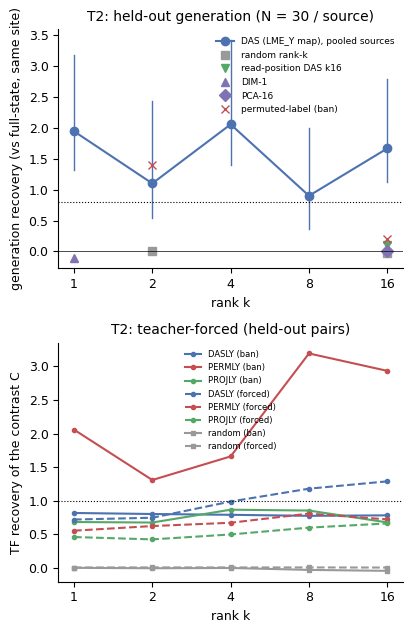

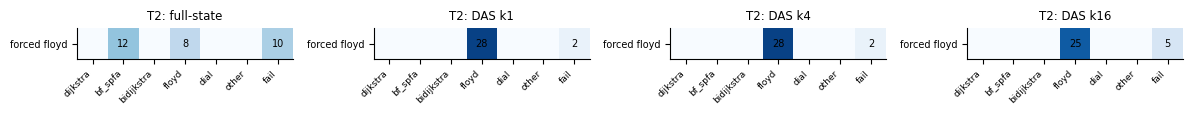

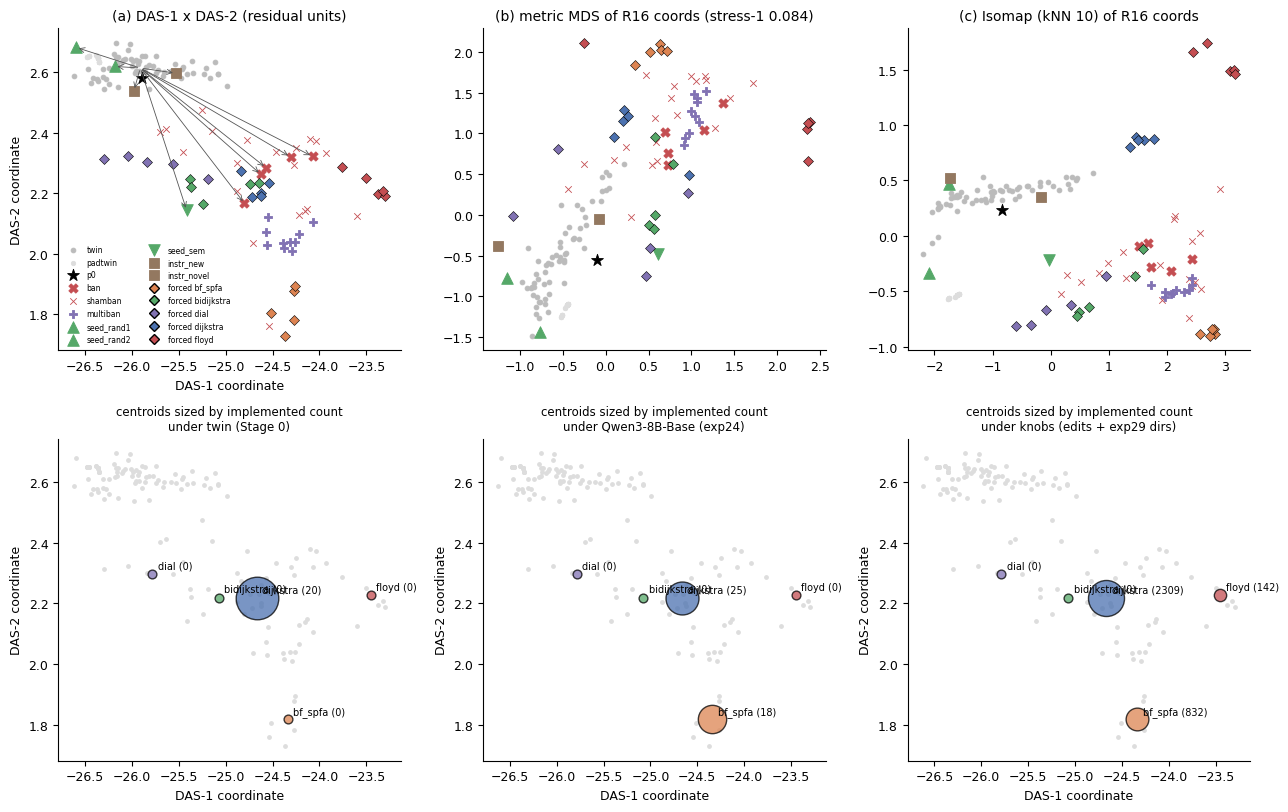

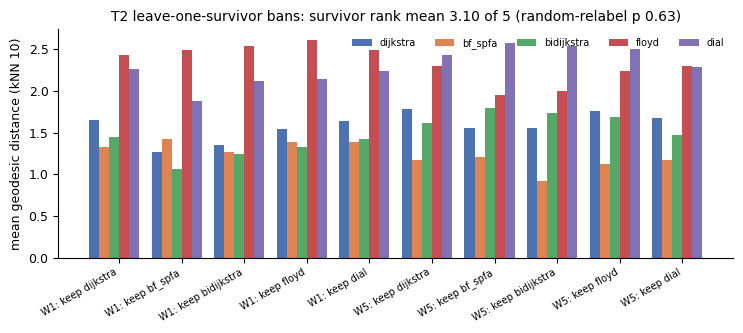

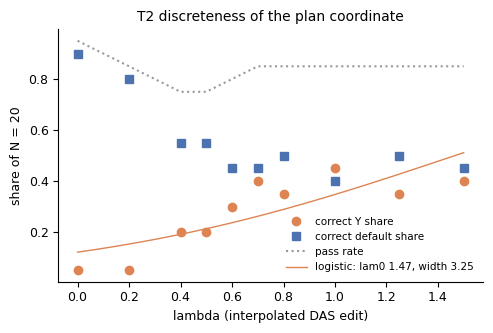

In [22]:
f2(p1, tasks)                  # F2: recovery vs rank (top: generation, re-derived; bottom: saved teacher-forced)
f3(rt)                         # F3: routing confusion, forced Floyd-Warshall source
f4(m)                          # F4: causal manifold in actual R16 activation coordinates (DAS plane, MDS, Isomap)
f5(m)                          # F5: leave-one-survivor ban placement (geodesic distances, kNN 10)
f6({**rr_saved, "fit": fit})   # F6: lambda sweep with the refitted logistic

### What the demo leaves out, and how to run everything

- **Not re-run, saved results shown instead:**
  - the dormant checks (`analysis7.dormant`), which need the 4096-d natural-state caches and the fitted maps;
  - the null-source and reverse-interchange cells and the forced Bellman-Ford source, whose rows are outside the
    100-example subset;
  - T10 and T03;
  - the novelty audit and the independent re-derivation (`audit/rederive.py`).
- **Full run.** In the artifact folder, `bash restore.sh` builds the `.venv` and downloads Qwen3-8B@b968826d. Then
  run `.venv/bin/python method.py`, or set `RUN_FULL_PIPELINE = True` in this notebook from that folder. One CUDA
  GPU with ≥ 24 GB is needed; the run takes about 1.6 GPU-hours. OpenRouter keys are used only by the judges.